<a href="https://colab.research.google.com/github/sbmedtech/isles2022-stroke-mri-segmentation/blob/main/ISLES_2022_First_Colab_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ISLES 2022 — Multimodal 3D stroke MRI segmentation

**Goal:** Download the official ISLES 2022 data, visualize DWI/ADC/FLAIR and expert masks, and train a **MONAI 3D U-Net with DWI, ADC, and FLAIR inputs** on patient-separated training, validation, and internal test cases. This is a research and learning prototype, not a clinical device.

**Results status:** saved outputs are historical notebook results, not independently reproduced or verified. Split files, checkpoints, evaluation CSVs, and standalone figures are saved outside the repository. See README.md for methodology, metrics, setup caveats, and reproducibility limitations.

The workflow uses Google Colab (`Runtime → Change runtime type → T4 GPU` if available), Google Drive under `/content/drive/MyDrive/ISLES2022_Project`, and temporary local tensor caching under `/content/isles2022_preprocessed`. The archive is approximately **1.69 GB**; extracted data and intermediate arrays require additional space. Review cells before running in order: diagnostic and training cells update weights, and initial training can overwrite checkpoints.

The source images are in native spaces: **do not overlay or stack sequences without checking their shapes and affines**. FLAIR resampling onto the DWI grid does not establish anatomical registration.

Official dataset: https://zenodo.org/records/7960856 . Original publication: https://doi.org/10.1038/s41597-022-01875-5 .


## 1 — Install dependencies and check GPU

In [1]:
%pip -q install nibabel scipy matplotlib tqdm
import os, glob, random, pathlib, zipfile, urllib.request
import numpy as np, nibabel as nib, matplotlib.pyplot as plt
import torch
print('PyTorch:',torch.__version__, 'GPU available:',torch.cuda.is_available())
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
random.seed(42); np.random.seed(42); torch.manual_seed(42)

PyTorch: 2.11.0+cu130 GPU available: True


## 2 — Download the official dataset to Google Drive

The following cells mount Google Drive and store the archive and extracted data under `/content/drive/MyDrive/ISLES2022_Project/data`. Later cells cache preprocessed training and validation tensors in temporary Colab local storage. Drive files persist separately from the runtime; the local cache can disappear when the runtime ends.

The download cell skips an existing archive when its byte size matches Zenodo metadata; it does not verify a cryptographic checksum. If downloading fails, consult the official Zenodo record and the file locations expected by the notebook. Dependencies and runtime versions are not pinned.


In [5]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)


Mounted at /content/drive


In [6]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/ISLES2022_Project")

DATA_DIR = PROJECT_DIR / "data"
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"

for folder in [DATA_DIR, MODEL_DIR, RESULTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folders created successfully!")

for folder in PROJECT_DIR.iterdir():
    print(folder.name)


Project folders created successfully!
data
models
results


In [7]:

# ============================================================
# STEP 3A: FIND THE OFFICIAL ISLES 2022 DATASET FILES
# ============================================================

# requests allows Python to communicate with websites and APIs.
import requests

# This is the Zenodo record containing the ISLES 2022 dataset.
# Zenodo is a scientific research data repository.
record_id = "7960856"

# Zenodo provides an API that lists the files associated
# with a dataset, including filenames, sizes, and download URLs.
api_url = f"https://zenodo.org/api/records/{record_id}"

# Request the dataset's metadata from Zenodo.
response = requests.get(api_url, timeout=60)

# Stop and show an error if the request was unsuccessful.
response.raise_for_status()

# Convert the response into a Python dictionary.
metadata = response.json()

# Extract the list of available dataset files.
files = metadata["files"]

# Print each filename and its size in gigabytes.
# This helps us identify the correct archive to download.
for file in files:
    filename = file["key"]
    size_gb = file["size"] / (1024 ** 3)

    print(f"Filename: {filename}")
    print(f"Size: {size_gb:.2f} GB")
    print("-" * 40)


Filename: center_ids.xlsx
Size: 0.00 GB
----------------------------------------
Filename: ISLES-2022.zip
Size: 1.58 GB
----------------------------------------


## 3 — Discover patient files (BIDS-style directories)

In [8]:

# ============================================================
# STEP 3B: DOWNLOAD THE ISLES 2022 DATASET
# ============================================================

# requests downloads files from the internet.
import requests

# tqdm displays a progress bar while downloading.
from tqdm.auto import tqdm

# Path allows us to work with folders and filenames.
from pathlib import Path

# ------------------------------------------------------------
# 1. DEFINE WHERE TO SAVE THE DATASET
# ------------------------------------------------------------

# This is the Google Drive project folder we created earlier.
PROJECT_DIR = Path("/content/drive/MyDrive/ISLES2022_Project")

# The data folder will contain our MRI dataset.
DATA_DIR = PROJECT_DIR / "data"

# Create the folder if it doesn't already exist.
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Define the full path for the downloaded ZIP file.
zip_path = DATA_DIR / "ISLES-2022.zip"

# ------------------------------------------------------------
# 2. IDENTIFY THE OFFICIAL DOWNLOAD URL
# ------------------------------------------------------------

# Retrieve the official file URL from Zenodo's metadata.
record_url = "https://zenodo.org/api/records/7960856"

response = requests.get(record_url, timeout=60)
response.raise_for_status()

metadata = response.json()

# Find the file named ISLES-2022.zip.
dataset_file = next(
    file for file in metadata["files"]
    if file["key"] == "ISLES-2022.zip"
)

# Use the download link supplied by Zenodo.
download_url = dataset_file["links"]["self"]

# Get the expected file size in bytes.
expected_size = dataset_file["size"]

# ------------------------------------------------------------
# 3. DOWNLOAD THE FILE
# ------------------------------------------------------------

# If the complete ZIP already exists, avoid downloading again.
if zip_path.exists() and zip_path.stat().st_size == expected_size:

    print("Dataset already downloaded!")
    print("Skipping download.")

else:

    print("Starting ISLES 2022 download...")

    # Stream the download instead of loading 1.58 GB into RAM.
    with requests.get(
        download_url,
        stream=True,
        timeout=(30, 120)
    ) as r:

        # Stop if Zenodo returns an HTTP error.
        r.raise_for_status()

        # Open the destination file in binary write mode.
        with open(zip_path, "wb") as f:

            # Create a progress bar showing total bytes.
            with tqdm(
                total=expected_size,
                unit="B",
                unit_scale=True,
                desc="Downloading ISLES 2022"
            ) as progress:

                # Download in chunks of 8 megabytes.
                for chunk in r.iter_content(
                    chunk_size=8 * 1024 * 1024
                ):

                    if chunk:
                        # Save each chunk to Google Drive.
                        f.write(chunk)

                        # Update the progress bar.
                        progress.update(len(chunk))

# ------------------------------------------------------------
# 4. VERIFY THE DOWNLOAD SIZE
# ------------------------------------------------------------

actual_size = zip_path.stat().st_size

print("\nDownload finished!")
print(f"Expected bytes: {expected_size:,}")
print(f"Downloaded bytes: {actual_size:,}")

# Check that the downloaded size matches Zenodo's metadata.
assert actual_size == expected_size, (
    "Download is incomplete. Please retry."
)

print("File size verified successfully!")


Starting ISLES 2022 download...



Download finished!
Expected bytes: 1,692,717,470
Downloaded bytes: 1,692,717,470
File size verified successfully!


In [9]:

# ============================================================
# STEP 3C: EXTRACT AND INSPECT THE ISLES 2022 DATASET
# ============================================================

# zipfile is a built-in Python library for working with ZIP files.
import zipfile

# pathlib makes it easier to work with folders and file paths.
from pathlib import Path

# ------------------------------------------------------------
# 1. DEFINE OUR FILE LOCATIONS
# ------------------------------------------------------------

# Main project folder in Google Drive.
PROJECT_DIR = Path("/content/drive/MyDrive/ISLES2022_Project")

# Folder containing the downloaded ZIP file.
DATA_DIR = PROJECT_DIR / "data"

# Location of the ZIP archive we downloaded in Step 3B.
zip_path = DATA_DIR / "ISLES-2022.zip"

# Folder where we want to extract the MRI dataset.
extract_dir = DATA_DIR / "extracted"

# Create the extraction folder if it doesn't already exist.
extract_dir.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. VERIFY THE ZIP FILE EXISTS AND IS READABLE
# ------------------------------------------------------------

# Confirm that the download is present.
assert zip_path.exists(), "ZIP file not found!"

print("ZIP file found!")

# Open the ZIP archive without extracting anything yet.
with zipfile.ZipFile(zip_path, "r") as z:

    # Retrieve the list of files inside the archive.
    archive_files = z.namelist()

    # Display how many files the archive contains.
    print(f"Files inside ZIP: {len(archive_files)}")

    # Show the first 15 filenames.
    print("\nFirst 15 files:")
    for filename in archive_files[:15]:
        print(filename)

    # --------------------------------------------------------
    # 3. EXTRACT THE DATASET
    # --------------------------------------------------------

    print("\nStarting extraction...")

    # Extract all files into our Google Drive folder.
    # This may take several minutes because MRI datasets
    # contain many individual files.
    z.extractall(extract_dir)

print("\nExtraction complete!")

# ------------------------------------------------------------
# 4. INSPECT THE EXTRACTED FOLDER STRUCTURE
# ------------------------------------------------------------

print("\nTop-level extracted folders and files:")

# Print the immediate contents of the extraction directory.
for item in sorted(extract_dir.iterdir()):
    print(
        "[DIR]" if item.is_dir() else "[FILE]",
        item.name
    )

# ------------------------------------------------------------
# 5. COUNT THE MRI AND SEGMENTATION FILES
# ------------------------------------------------------------

# NIfTI is a standard file format for medical imaging.
# Most ISLES MRI scans and lesion masks use .nii.gz.

nifti_files = list(extract_dir.rglob("*.nii.gz"))

print("\nTotal NIfTI files found:", len(nifti_files))

# Display a small sample so we can inspect naming conventions.
print("\nFirst 10 NIfTI files:")

for file in nifti_files[:10]:
    print(file.relative_to(extract_dir))


ZIP file found!
Files inside ZIP: 3190

First 15 files:
ISLES-2022/
ISLES-2022/sub-strokecase0140/
ISLES-2022/sub-strokecase0140/ses-0001/
ISLES-2022/sub-strokecase0140/ses-0001/anat/
ISLES-2022/sub-strokecase0140/ses-0001/anat/sub-strokecase0140_ses-0001_FLAIR.nii.gz
ISLES-2022/sub-strokecase0140/ses-0001/anat/sub-strokecase0140_ses-0001_FLAIR.json
ISLES-2022/sub-strokecase0140/ses-0001/dwi/
ISLES-2022/sub-strokecase0140/ses-0001/dwi/sub-strokecase0140_ses-0001_dwi.nii.gz
ISLES-2022/sub-strokecase0140/ses-0001/dwi/sub-strokecase0140_ses-0001_adc.nii.gz
ISLES-2022/sub-strokecase0140/ses-0001/dwi/sub-strokecase0140_ses-0001_dwi.json
ISLES-2022/sub-strokecase0140/ses-0001/dwi/sub-strokecase0140_ses-0001_adc.json
ISLES-2022/sub-strokecase0221/
ISLES-2022/sub-strokecase0221/ses-0001/
ISLES-2022/sub-strokecase0221/ses-0001/anat/
ISLES-2022/sub-strokecase0221/ses-0001/anat/sub-strokecase0221_ses-0001_FLAIR.nii.gz

Starting extraction...

Extraction complete!

Top-level extracted folders and 

## 4 — Visualize one stroke and its expert lesion mask

We display each MRI in its own native voxel grid, and resample the **mask** to the DWI grid using nearest-neighbor interpolation for the overlay. The displayed ADC and FLAIR slices are illustrative native slices and are **not spatially registered** to DWI.

In [10]:

# ============================================================
# STEP 4A: IDENTIFY THE EXPERT SEGMENTATION MASKS
# ============================================================

from pathlib import Path
from collections import Counter

# ------------------------------------------------------------
# 1. LOCATE THE EXTRACTED DATASET
# ------------------------------------------------------------

# This is the folder created during extraction.
DATASET_DIR = Path(
    "/content/drive/MyDrive/ISLES2022_Project/"
    "data/extracted/ISLES-2022"
)

# Verify that the dataset folder exists.
assert DATASET_DIR.exists(), "Dataset folder not found!"

# ------------------------------------------------------------
# 2. FIND ALL NIFTI FILES
# ------------------------------------------------------------

# rglob searches recursively through all subfolders.
# NIfTI files contain our 3D MRI volumes and lesion masks.
nifti_files = sorted(DATASET_DIR.rglob("*.nii.gz"))

print("Total NIfTI files:", len(nifti_files))

# ------------------------------------------------------------
# 3. IDENTIFY FILES THAT MAY BE SEGMENTATION MASKS
# ------------------------------------------------------------

# Segmentation files commonly contain terms such as
# 'mask', 'lesion', 'seg', or 'msk' in their filenames.
keywords = ["mask", "lesion", "seg", "msk"]

mask_files = [
    file for file in nifti_files
    if any(word in file.name.lower() for word in keywords)
]

print("\nPotential segmentation masks:", len(mask_files))

# Display the first 10 matching filenames.
for file in mask_files[:10]:
    print(file.relative_to(DATASET_DIR))

# ------------------------------------------------------------
# 4. COUNT FILES BY THEIR PARENT FOLDER
# ------------------------------------------------------------

# This helps us discover whether segmentation masks
# are stored in a separate directory such as 'derivatives'.
folder_counts = Counter(
    file.parent.name for file in nifti_files
)

print("\nNIfTI files by parent folder:")

for folder, count in sorted(folder_counts.items()):
    print(f"{folder}: {count}")

# ------------------------------------------------------------
# 5. INSPECT TOP-LEVEL DATASET FOLDERS
# ------------------------------------------------------------

print("\nDataset root contents:")

for item in sorted(DATASET_DIR.iterdir()):
    if item.is_dir() and not item.name.startswith("sub-"):
        print("[DIR]", item.name)
    elif item.is_file():
        print("[FILE]", item.name)


Total NIfTI files: 1000

Potential segmentation masks: 250
derivatives/sub-strokecase0001/ses-0001/sub-strokecase0001_ses-0001_msk.nii.gz
derivatives/sub-strokecase0002/ses-0001/sub-strokecase0002_ses-0001_msk.nii.gz
derivatives/sub-strokecase0003/ses-0001/sub-strokecase0003_ses-0001_msk.nii.gz
derivatives/sub-strokecase0004/ses-0001/sub-strokecase0004_ses-0001_msk.nii.gz
derivatives/sub-strokecase0005/ses-0001/sub-strokecase0005_ses-0001_msk.nii.gz
derivatives/sub-strokecase0006/ses-0001/sub-strokecase0006_ses-0001_msk.nii.gz
derivatives/sub-strokecase0007/ses-0001/sub-strokecase0007_ses-0001_msk.nii.gz
derivatives/sub-strokecase0008/ses-0001/sub-strokecase0008_ses-0001_msk.nii.gz
derivatives/sub-strokecase0009/ses-0001/sub-strokecase0009_ses-0001_msk.nii.gz
derivatives/sub-strokecase0010/ses-0001/sub-strokecase0010_ses-0001_msk.nii.gz

NIfTI files by parent folder:
anat: 250
dwi: 500
ses-0001: 250

Dataset root contents:
[FILE] LICENSE
[FILE] README
[FILE] dataset_description.json
[D

In [11]:

# ============================================================
# STEP 4B.1: INSTALL NIBABEL
# ============================================================

# nibabel is a Python library for reading medical imaging
# formats, including NIfTI (.nii.gz).
#
# It lets us load 3D MRI volumes as NumPy arrays.
#
# The -q flag installs quietly without printing
# unnecessary installation messages.

!pip -q install nibabel


In [12]:

# ============================================================
# STEP 4B.2: LOAD OUR FIRST STROKE MRI
# ============================================================

import nibabel as nib
import numpy as np
from pathlib import Path

# ------------------------------------------------------------
# 1. IDENTIFY THE PATIENT
# ------------------------------------------------------------

# Start with stroke case 0001.
# Later, we'll automatically load all 250 cases.
case_id = "sub-strokecase0001"
session = "ses-0001"

# Root directory of the extracted dataset.
DATASET_DIR = Path(
    "/content/drive/MyDrive/ISLES2022_Project/"
    "data/extracted/ISLES-2022"
)

# ------------------------------------------------------------
# 2. BUILD THE FILE PATHS
# ------------------------------------------------------------

# Each imaging modality has a separate NIfTI file.
# The expert segmentation is stored under derivatives.

case_dir = DATASET_DIR / case_id / session

dwi_path = (
    case_dir / "dwi" /
    f"{case_id}_{session}_dwi.nii.gz"
)

adc_path = (
    case_dir / "dwi" /
    f"{case_id}_{session}_adc.nii.gz"
)

flair_path = (
    case_dir / "anat" /
    f"{case_id}_{session}_FLAIR.nii.gz"
)

mask_path = (
    DATASET_DIR / "derivatives" /
    case_id / session /
    f"{case_id}_{session}_msk.nii.gz"
)

# ------------------------------------------------------------
# 3. VERIFY ALL FOUR FILES EXIST
# ------------------------------------------------------------

for path in [dwi_path, adc_path, flair_path, mask_path]:
    assert path.exists(), f"Missing file: {path}"

print("All four files located successfully!")

# ------------------------------------------------------------
# 4. LOAD THE 3D MRI VOLUMES
# ------------------------------------------------------------

# nib.load reads the NIfTI image header and provides
# access to the image data.
#
# get_fdata() converts the voxel intensities into
# a NumPy array, which we can visualize and analyze.

dwi_img = nib.load(str(dwi_path))
adc_img = nib.load(str(adc_path))
flair_img = nib.load(str(flair_path))
mask_img = nib.load(str(mask_path))

dwi = dwi_img.get_fdata()
adc = adc_img.get_fdata()
flair = flair_img.get_fdata()
mask = mask_img.get_fdata()

# ------------------------------------------------------------
# 5. INSPECT IMAGE DIMENSIONS
# ------------------------------------------------------------

# Shape describes the number of voxels along each axis.
# Different MRI sequences may have different dimensions.
#
# We must check this before overlaying images.

print("\nImage dimensions:")
print("DWI:  ", dwi.shape)
print("ADC:  ", adc.shape)
print("FLAIR:", flair.shape)
print("MASK: ", mask.shape)

# Print unique values in the segmentation mask.
# A binary segmentation generally contains:
# 0 = background
# 1 = ischemic lesion

print("\nUnique mask values:", np.unique(mask))


All four files located successfully!

Image dimensions:
DWI:   (112, 112, 73)
ADC:   (112, 112, 73)
FLAIR: (281, 352, 352)
MASK:  (112, 112, 73)

Unique mask values: [0. 1.]


DWI and mask share the same voxel grid.
Selected slice index: 44
Lesion voxels in selected slice: 54


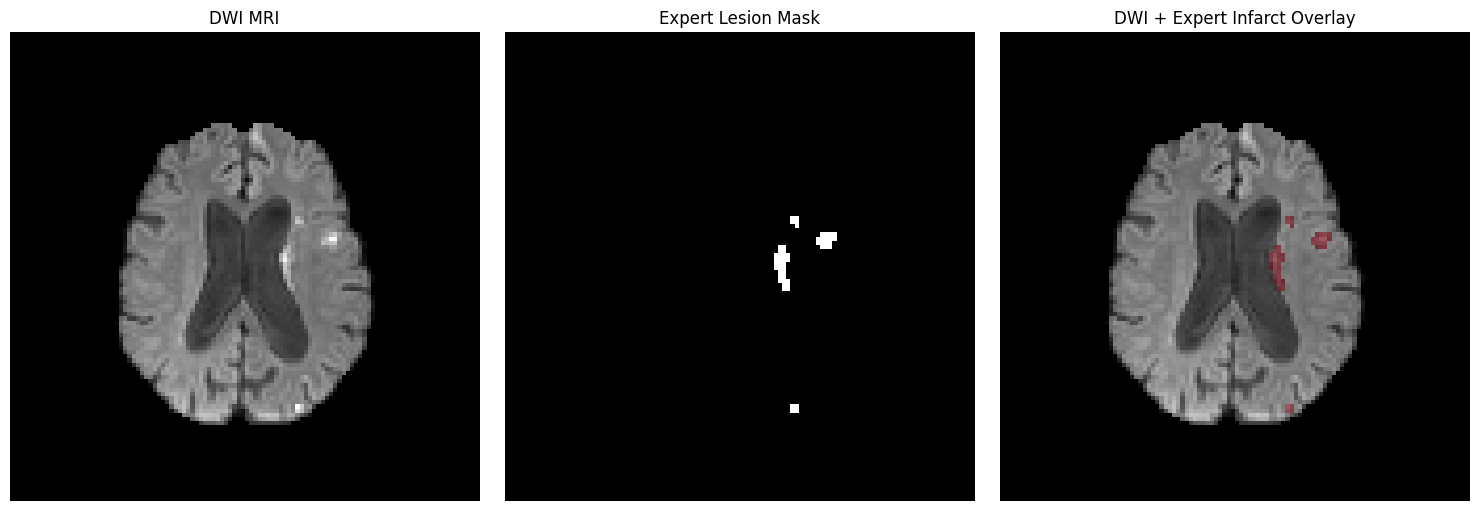

In [13]:

# ============================================================
# STEP 4C: VISUALIZE THE STROKE AND EXPERT SEGMENTATION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. VERIFY DWI AND MASK SPATIAL ALIGNMENT
# ------------------------------------------------------------

# Both arrays have matching dimensions, but we must also
# verify their NIfTI affine matrices.
#
# An affine matrix describes how voxel coordinates map
# into physical space (typically millimeters).

assert dwi.shape == mask.shape, (
    "DWI and mask dimensions do not match!"
)

assert np.allclose(dwi_img.affine, mask_img.affine), (
    "DWI and mask affines differ. Registration is needed."
)

print("DWI and mask share the same voxel grid.")

# ------------------------------------------------------------
# 2. FIND THE SLICE WITH THE MOST LESION VOXELS
# ------------------------------------------------------------

# The third array axis is the slice axis for this volume.
#
# Count the number of lesion voxels in each slice.
lesion_voxels_per_slice = np.sum(
    mask > 0,
    axis=(0, 1)
)

# Find the slice with the highest lesion voxel count.
slice_index = int(np.argmax(lesion_voxels_per_slice))

print("Selected slice index:", slice_index)
print(
    "Lesion voxels in selected slice:",
    int(lesion_voxels_per_slice[slice_index])
)

# ------------------------------------------------------------
# 3. EXTRACT THE SELECTED 2D SLICE
# ------------------------------------------------------------

# Select one 2D slice from each 3D volume.
dwi_slice = dwi[:, :, slice_index]
mask_slice = mask[:, :, slice_index]

# Rotate both arrays identically for easier viewing.
# This is a display operation, not spatial registration.
dwi_display = np.rot90(dwi_slice)
mask_display = np.rot90(mask_slice)

# ------------------------------------------------------------
# 4. CREATE THE VISUALIZATION
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# PANEL 1: Original DWI image.
axes[0].imshow(dwi_display, cmap="gray")
axes[0].set_title("DWI MRI")

# PANEL 2: Expert segmentation mask.
axes[1].imshow(mask_display, cmap="gray")
axes[1].set_title("Expert Lesion Mask")

# PANEL 3: DWI with a red lesion overlay.
axes[2].imshow(dwi_display, cmap="gray")

# Mask non-lesion voxels so only annotated infarct
# regions appear in red.
red_overlay = np.ma.masked_where(
    mask_display == 0,
    mask_display
)

axes[2].imshow(
    red_overlay,
    cmap="Reds",
    alpha=0.65,
    vmin=0,
    vmax=1
)

axes[2].set_title("DWI + Expert Infarct Overlay")

# Remove axis ticks for a cleaner presentation.
for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


DWI and ADC share the same voxel grid.


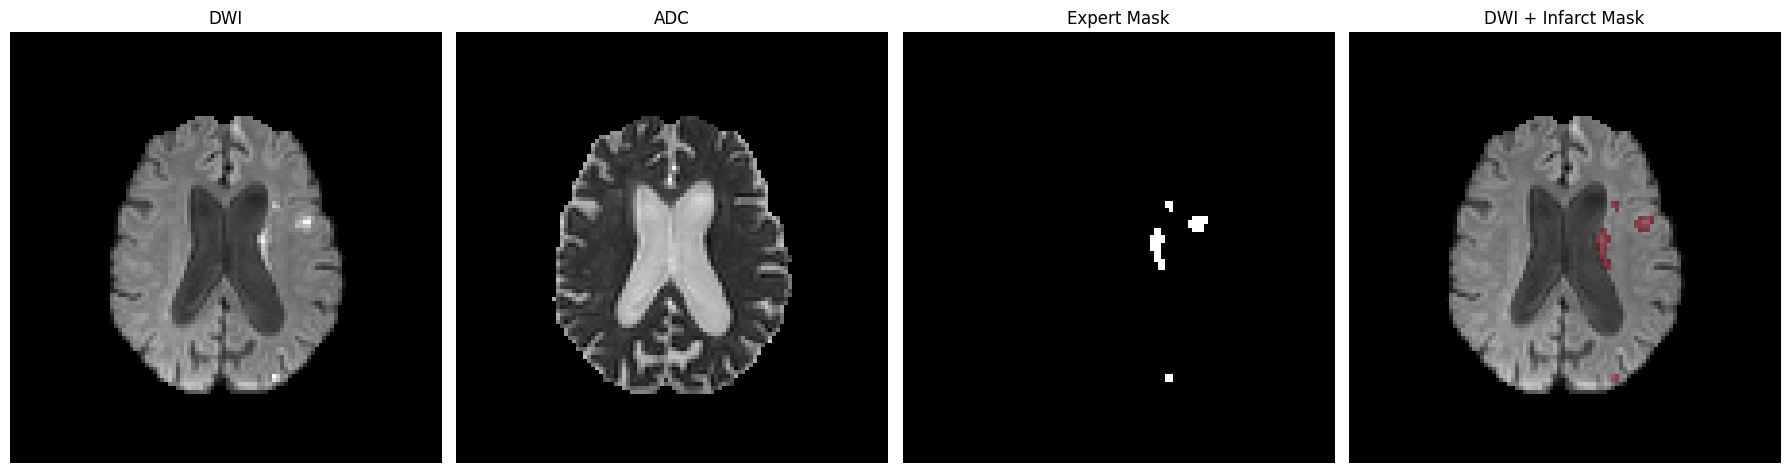

In [14]:

# ============================================================
# STEP 4D: VISUALIZE DWI AND ADC WITH EXPERT ANNOTATIONS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. CHECK THAT DWI AND ADC ARE SPATIALLY ALIGNED
# ------------------------------------------------------------

# Matching array dimensions are not sufficient to prove
# alignment. The affine matrices must also agree.

assert dwi.shape == adc.shape, (
    "DWI and ADC have different array dimensions."
)

assert np.allclose(dwi_img.affine, adc_img.affine), (
    "DWI and ADC have different spatial coordinates."
)

print("DWI and ADC share the same voxel grid.")

# ------------------------------------------------------------
# 2. SELECT THE SAME SLICE AS BEFORE
# ------------------------------------------------------------

# Reuse slice_index from our previous visualization.
# This ensures we're comparing the same anatomical level.

dwi_slice = np.rot90(dwi[:, :, slice_index])
adc_slice = np.rot90(adc[:, :, slice_index])
mask_slice = np.rot90(mask[:, :, slice_index])

# ------------------------------------------------------------
# 3. CREATE FOUR COMPARISON PANELS
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

# Original diffusion-weighted image.
axes[0].imshow(dwi_slice, cmap="gray")
axes[0].set_title("DWI")

# Apparent diffusion coefficient map.
axes[1].imshow(adc_slice, cmap="gray")
axes[1].set_title("ADC")

# Expert segmentation mask.
axes[2].imshow(mask_slice, cmap="gray")
axes[2].set_title("Expert Mask")

# DWI with expert infarct annotations.
axes[3].imshow(dwi_slice, cmap="gray")

# Display only the positive lesion voxels in red.
overlay = np.ma.masked_where(mask_slice == 0, mask_slice)

axes[3].imshow(
    overlay,
    cmap="Reds",
    alpha=0.65,
    vmin=0,
    vmax=1
)

axes[3].set_title("DWI + Infarct Mask")

# Remove axes for a cleaner clinical presentation.
for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


## Step 5 — Spatial grid checks and FLAIR resampling

The reusable preprocessing function uses DWI as the reference and requires ADC and expert masks to match its shape and affine. It resamples FLAIR onto the DWI voxel grid with NiBabel using linear interpolation.

This is **affine-based resampling, not an independently estimated anatomical registration**. Matching voxel grids does not guarantee anatomical correspondence across modalities. Inspect spatial alignment before interpreting multimodal predictions; registration-quality assessment remains future work.


Original FLAIR: (281, 352, 352)
Resampled FLAIR: (112, 112, 73)
DWI: (112, 112, 73)

FLAIR successfully resampled into DWI space!


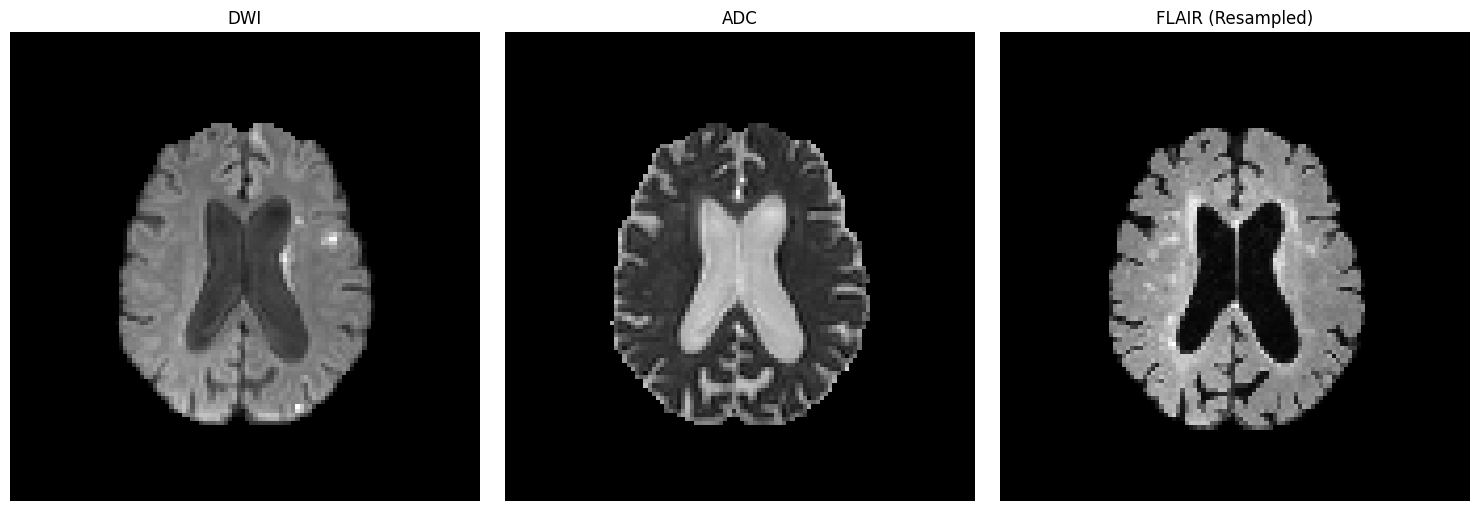

In [15]:

# ============================================================
# STEP 5A: RESAMPLE FLAIR INTO DWI SPACE
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# NiBabel provides functions for resampling medical images
# between different voxel grids.
from nibabel.processing import resample_from_to

# ------------------------------------------------------------
# 1. DEFINE OUR REFERENCE IMAGE
# ------------------------------------------------------------

# DWI will be our reference coordinate system.
#
# Our goal is to make FLAIR have the same:
# - Voxel dimensions
# - Spatial orientation
# - Image shape
# - Physical coordinate grid
#
# We already loaded these images in Step 4B:
# dwi_img, flair_img, mask_img

# ------------------------------------------------------------
# 2. RESAMPLE FLAIR INTO THE DWI GRID
# ------------------------------------------------------------

# resample_from_to uses the affine transformations stored
# in the NIfTI headers to map FLAIR into DWI coordinates.
#
# order=1 uses linear interpolation, which is appropriate
# for continuous MRI intensity values.
#
# We do NOT resample the binary segmentation mask here.
# If a mask ever needs resampling, we should use order=0
# (nearest-neighbor) to preserve its discrete labels.

flair_resampled_img = resample_from_to(
    flair_img,
    dwi_img,
    order=1
)

# Convert the resampled image into a NumPy array.
flair_resampled = flair_resampled_img.get_fdata()

# ------------------------------------------------------------
# 3. VERIFY THE NEW DIMENSIONS
# ------------------------------------------------------------

print("Original FLAIR:", flair.shape)
print("Resampled FLAIR:", flair_resampled.shape)
print("DWI:", dwi.shape)

# Confirm that the arrays now have matching dimensions.
assert flair_resampled.shape == dwi.shape

# Confirm that the physical coordinate systems match.
assert np.allclose(
    flair_resampled_img.affine,
    dwi_img.affine
)

print("\nFLAIR successfully resampled into DWI space!")

# ------------------------------------------------------------
# 4. VISUALIZE ALL THREE MRI SEQUENCES
# ------------------------------------------------------------

# Use the same axial slice we previously selected.
dwi_slice = np.rot90(dwi[:, :, slice_index])
adc_slice = np.rot90(adc[:, :, slice_index])
flair_slice = np.rot90(
    flair_resampled[:, :, slice_index]
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Display diffusion-weighted MRI.
axes[0].imshow(dwi_slice, cmap="gray")
axes[0].set_title("DWI")

# Display ADC map.
axes[1].imshow(adc_slice, cmap="gray")
axes[1].set_title("ADC")

# Display resampled FLAIR.
axes[2].imshow(flair_slice, cmap="gray")
axes[2].set_title("FLAIR (Resampled)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [16]:

# ============================================================
# STEP 5B.1: CREATE TRAINING, VALIDATION, AND TEST SPLITS
# ============================================================

from pathlib import Path
import random
import json

# ------------------------------------------------------------
# 1. DEFINE PROJECT DIRECTORIES
# ------------------------------------------------------------

# Main project folder in Google Drive.
PROJECT_DIR = Path(
    "/content/drive/MyDrive/ISLES2022_Project"
)

# Location of our extracted ISLES 2022 dataset.
DATASET_DIR = (
    PROJECT_DIR / "data" / "extracted" / "ISLES-2022"
)

# Create a folder for our dataset split information.
SPLITS_DIR = PROJECT_DIR / "splits"
SPLITS_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. IDENTIFY ALL PATIENTS
# ------------------------------------------------------------

# Each patient has a folder named sub-strokecaseXXXX.
# We only select directories beginning with "sub-".
patient_ids = sorted([
    folder.name
    for folder in DATASET_DIR.glob("sub-*")
    if folder.is_dir()
])

print("Total patients found:", len(patient_ids))

# We expect 250 cases in the ISLES 2022 dataset.
assert len(patient_ids) == 250, (
    f"Expected 250 patients, found {len(patient_ids)}"
)

# ------------------------------------------------------------
# 3. RANDOMIZE PATIENT ORDER
# ------------------------------------------------------------

# A fixed random seed ensures reproducibility.
# Every time we run this code, we get the same split.
random.seed(42)

shuffled_patients = patient_ids.copy()
random.shuffle(shuffled_patients)

# ------------------------------------------------------------
# 4. DIVIDE INTO THREE GROUPS
# ------------------------------------------------------------

# 70% training = 175 patients
# Approximately 15% validation = 37 patients
# Remaining 15% testing = 38 patients

train_ids = shuffled_patients[:175]
val_ids = shuffled_patients[175:212]
test_ids = shuffled_patients[212:]

# ------------------------------------------------------------
# 5. VERIFY NO PATIENT OVERLAP
# ------------------------------------------------------------

# A patient must never appear in multiple groups.
# Otherwise, our evaluation could be misleading.

assert set(train_ids).isdisjoint(val_ids)
assert set(train_ids).isdisjoint(test_ids)
assert set(val_ids).isdisjoint(test_ids)

# Verify all 250 patients are accounted for.
assert len(train_ids + val_ids + test_ids) == 250

print("\nDataset split successful!")
print("Training patients:", len(train_ids))
print("Validation patients:", len(val_ids))
print("Testing patients:", len(test_ids))

# ------------------------------------------------------------
# 6. SAVE SPLITS PERMANENTLY TO GOOGLE DRIVE
# ------------------------------------------------------------

# Saving the split is important for reproducibility.
# We want to use the exact same patients when comparing
# different neural network architectures.

split_data = {
    "random_seed": 42,
    "train": train_ids,
    "validation": val_ids,
    "test": test_ids
}

split_path = SPLITS_DIR / "patient_splits.json"

# Avoid silently overwriting an existing split.
if split_path.exists():
    with open(split_path, "r") as f:
        existing_splits = json.load(f)

    assert existing_splits == split_data, (
        "An existing patient split differs. "
        "Review it before continuing."
    )
    print("\nExisting patient split verified.")
else:
    with open(split_path, "w") as f:
        json.dump(split_data, f, indent=4)

    print("\nPatient splits saved successfully!")

print("Saved to:", split_path)


Total patients found: 250

Dataset split successful!
Training patients: 175
Validation patients: 37
Testing patients: 38

Patient splits saved successfully!
Saved to: /content/drive/MyDrive/ISLES2022_Project/splits/patient_splits.json


In [17]:

# ============================================================
# STEP 5B.2A: INSTALL MONAI
# ============================================================

# MONAI (Medical Open Network for AI) is a deep learning
# framework built on PyTorch specifically for medical imaging.
#
# We'll eventually use MONAI's 3D U-Net architecture,
# medical image transforms, and segmentation metrics.
#
# The -q option reduces installation output.

!pip -q install monai


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 17.0 MB/s eta 0:00:00


In [18]:

# ============================================================
# STEP 5B.2B: PREPROCESS ONE ISLES 2022 PATIENT
# ============================================================

import numpy as np
import torch
import nibabel as nib

from nibabel.processing import resample_from_to
from pathlib import Path

# ------------------------------------------------------------
# 1. DEFINE THE PATIENT AND DATASET LOCATION
# ------------------------------------------------------------

# We'll use the same case we've already visualized.
case_id = "sub-strokecase0001"
session = "ses-0001"

DATASET_DIR = Path(
    "/content/drive/MyDrive/ISLES2022_Project/"
    "data/extracted/ISLES-2022"
)

case_dir = DATASET_DIR / case_id / session

# ------------------------------------------------------------
# 2. DEFINE MRI AND SEGMENTATION PATHS
# ------------------------------------------------------------

dwi_path = (
    case_dir / "dwi" /
    f"{case_id}_{session}_dwi.nii.gz"
)

adc_path = (
    case_dir / "dwi" /
    f"{case_id}_{session}_adc.nii.gz"
)

flair_path = (
    case_dir / "anat" /
    f"{case_id}_{session}_FLAIR.nii.gz"
)

mask_path = (
    DATASET_DIR / "derivatives" /
    case_id / session /
    f"{case_id}_{session}_msk.nii.gz"
)

# ------------------------------------------------------------
# 3. LOAD THE FOUR NIFTI VOLUMES
# ------------------------------------------------------------

dwi_img = nib.load(str(dwi_path))
adc_img = nib.load(str(adc_path))
flair_img = nib.load(str(flair_path))
mask_img = nib.load(str(mask_path))

# ------------------------------------------------------------
# 4. VERIFY SPATIAL ALIGNMENT
# ------------------------------------------------------------

# DWI, ADC, and the expert mask should occupy the same
# physical voxel grid.
#
# We check both shape and affine transformation.
# If they differ, stop rather than silently combining
# misaligned images.

for name, img in [
    ("ADC", adc_img),
    ("Mask", mask_img)
]:
    assert img.shape == dwi_img.shape, (
        f"{name} shape differs from DWI."
    )

    assert np.allclose(img.affine, dwi_img.affine), (
        f"{name} affine differs from DWI."
    )

# ------------------------------------------------------------
# 5. RESAMPLE FLAIR INTO DWI SPACE
# ------------------------------------------------------------

# Linear interpolation is suitable for continuous MRI
# intensity data.
#
# This aligns voxel grids using NIfTI spatial metadata.
# It does not independently perform image registration.

flair_aligned_img = resample_from_to(
    flair_img,
    dwi_img,
    order=1
)

# ------------------------------------------------------------
# 6. CONVERT IMAGES TO NUMPY ARRAYS
# ------------------------------------------------------------

dwi = dwi_img.get_fdata(dtype=np.float32)
adc = adc_img.get_fdata(dtype=np.float32)
flair = flair_aligned_img.get_fdata(dtype=np.float32)
mask = mask_img.get_fdata(dtype=np.float32)

# ------------------------------------------------------------
# 7. NORMALIZE MRI INTENSITIES
# ------------------------------------------------------------

# MRI intensity scales differ across sequences and scanners.
#
# We normalize each channel separately using the mean
# and standard deviation of nonzero, finite voxels.
#
# This is per-patient normalization and does not use
# statistics from other patients.

def normalize_mri(volume):

    # Remove NaN or infinite values if present.
    volume = np.nan_to_num(
        volume,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    # Identify voxels containing nonzero image values.
    valid = volume != 0

    # Handle an entirely empty image safely.
    if not np.any(valid):
        return np.zeros_like(volume, dtype=np.float32)

    # Calculate statistics from nonzero voxels only.
    mean = volume[valid].mean()
    std = volume[valid].std()

    # Avoid division by zero.
    std = max(float(std), 1e-8)

    # Apply z-score normalization.
    normalized = np.zeros_like(volume, dtype=np.float32)

    normalized[valid] = (
        volume[valid] - mean
    ) / std

    return normalized

dwi_norm = normalize_mri(dwi)
adc_norm = normalize_mri(adc)
flair_norm = normalize_mri(flair)

# ------------------------------------------------------------
# 8. COMBINE THE THREE MRI CHANNELS
# ------------------------------------------------------------

# Stack DWI, ADC, and FLAIR into one NumPy array.
#
# The resulting dimensions are:
# (Channels, X, Y, Z)
#
# Channel 0 = DWI
# Channel 1 = ADC
# Channel 2 = FLAIR

image_array = np.stack(
    [dwi_norm, adc_norm, flair_norm],
    axis=0
)

# Add a channel dimension to the expert mask.
# This gives the mask shape (1, X, Y, Z).
mask_array = (mask > 0).astype(np.float32)[None, ...]

# ------------------------------------------------------------
# 9. CONVERT ARRAYS INTO PYTORCH TENSORS
# ------------------------------------------------------------

# PyTorch tensors are the data structures used for
# neural network training.

image_tensor = torch.from_numpy(image_array.copy())
mask_tensor = torch.from_numpy(mask_array.copy())

# ------------------------------------------------------------
# 10. VERIFY OUR PREPROCESSED DATA
# ------------------------------------------------------------

print("Preprocessing successful!")

print("\nImage tensor shape:", image_tensor.shape)
print("Mask tensor shape:", mask_tensor.shape)

print("\nImage dtype:", image_tensor.dtype)
print("Mask dtype:", mask_tensor.dtype)

print("\nUnique mask values:", torch.unique(mask_tensor))

# Confirm that no invalid numerical values remain.
assert torch.isfinite(image_tensor).all()
assert torch.isfinite(mask_tensor).all()

# Confirm that the MRI and mask dimensions match.
assert image_tensor.shape[1:] == mask_tensor.shape[1:]

print("\nAll preprocessing checks passed!")


Preprocessing successful!

Image tensor shape: torch.Size([3, 112, 112, 73])
Mask tensor shape: torch.Size([1, 112, 112, 73])

Image dtype: torch.float32
Mask dtype: torch.float32

Unique mask values: tensor([0., 1.])

All preprocessing checks passed!


In [19]:

# ============================================================
# STEP 5B.3: REUSABLE MRI PREPROCESSING FUNCTION
# ============================================================

import numpy as np
import torch
import nibabel as nib

from nibabel.processing import resample_from_to

# ------------------------------------------------------------
# 1. DEFINE OUR PREPROCESSING FUNCTION
# ------------------------------------------------------------

def preprocess_patient(case_id):
    """
    Load and preprocess one ISLES 2022 stroke case.

    Parameters
    ----------
    case_id : str
        Patient identifier, e.g. 'sub-strokecase0001'.

    Returns
    -------
    image_tensor : torch.Tensor
        Three MRI channels (DWI, ADC, FLAIR).

    mask_tensor : torch.Tensor
        Binary expert ischemic lesion segmentation.
    """

    # All cases use session 0001 in our dataset.
    session = "ses-0001"

    # Identify the patient's imaging directory.
    case_dir = DATASET_DIR / case_id / session

    # Construct paths for the three MRI modalities.
    dwi_path = (
        case_dir / "dwi" /
        f"{case_id}_{session}_dwi.nii.gz"
    )

    adc_path = (
        case_dir / "dwi" /
        f"{case_id}_{session}_adc.nii.gz"
    )

    flair_path = (
        case_dir / "anat" /
        f"{case_id}_{session}_FLAIR.nii.gz"
    )

    # Expert segmentation masks are stored separately
    # under the derivatives directory.
    mask_path = (
        DATASET_DIR / "derivatives" /
        case_id / session /
        f"{case_id}_{session}_msk.nii.gz"
    )

    # --------------------------------------------------------
    # 2. LOAD THE NIFTI IMAGES
    # --------------------------------------------------------

    # Verify all required files are present.
    for path in [dwi_path, adc_path, flair_path, mask_path]:
        if not path.exists():
            raise FileNotFoundError(f"Missing: {path}")

    dwi_img = nib.load(str(dwi_path))
    adc_img = nib.load(str(adc_path))
    flair_img = nib.load(str(flair_path))
    mask_img = nib.load(str(mask_path))

    # --------------------------------------------------------
    # 3. VERIFY DWI, ADC, AND MASK ALIGNMENT
    # --------------------------------------------------------

    # Both voxel dimensions and spatial transformations
    # must match before combining these arrays.
    for name, img in [
        ("ADC", adc_img),
        ("Mask", mask_img)
    ]:
        if (
            img.shape != dwi_img.shape
            or not np.allclose(img.affine, dwi_img.affine)
        ):
            raise ValueError(
                f"{case_id}: {name} grid differs from DWI"
            )

    # --------------------------------------------------------
    # 4. RESAMPLE FLAIR INTO DWI SPACE
    # --------------------------------------------------------

    # Linear interpolation preserves continuous MRI
    # intensities better than nearest-neighbor interpolation.
    #
    # This is affine-based resampling, not independent
    # anatomical registration.
    flair_aligned = resample_from_to(
        flair_img,
        dwi_img,
        order=1
    )

    # --------------------------------------------------------
    # 5. EXTRACT THE IMAGE ARRAYS
    # --------------------------------------------------------

    dwi = dwi_img.get_fdata(dtype=np.float32)
    adc = adc_img.get_fdata(dtype=np.float32)
    flair = flair_aligned.get_fdata(dtype=np.float32)
    mask = mask_img.get_fdata(dtype=np.float32)

    # --------------------------------------------------------
    # 6. NORMALIZE THE MRI INTENSITIES
    # --------------------------------------------------------

    # Reuse the normalize_mri() function we defined
    # in Step 5B.2.
    #
    # Each sequence is normalized independently.
    dwi = normalize_mri(dwi)
    adc = normalize_mri(adc)
    flair = normalize_mri(flair)

    # --------------------------------------------------------
    # 7. COMBINE INTO PYTORCH TENSORS
    # --------------------------------------------------------

    # Three MRI channels:
    # Channel 0 = DWI
    # Channel 1 = ADC
    # Channel 2 = FLAIR
    image = np.stack(
        [dwi, adc, flair],
        axis=0
    )

    # Convert expert annotations into a binary mask.
    # Add a channel dimension for segmentation training.
    mask = (mask > 0).astype(np.float32)[None, ...]

    # Convert NumPy arrays into PyTorch tensors.
    image_tensor = torch.from_numpy(
        np.ascontiguousarray(image)
    )

    mask_tensor = torch.from_numpy(
        np.ascontiguousarray(mask)
    )

    # --------------------------------------------------------
    # 8. FINAL QUALITY CHECKS
    # --------------------------------------------------------

    # Ensure images and labels have matching spatial shape.
    assert image_tensor.shape[1:] == mask_tensor.shape[1:]

    # Ensure there are no NaN or infinite values.
    assert torch.isfinite(image_tensor).all()
    assert torch.isfinite(mask_tensor).all()

    return image_tensor, mask_tensor


# ============================================================
# STEP 5B.3B: TEST ON THREE PATIENTS
# ============================================================

# Use three patients from the training split.
# We avoid validation/test patients during development.
sample_patients = train_ids[:3]

for patient in sample_patients:

    print(f"\nProcessing {patient}...")

    # Preprocess this patient's MRI and segmentation.
    image, label = preprocess_patient(patient)

    # Display the resulting tensor dimensions.
    print("MRI shape:", tuple(image.shape))
    print("Mask shape:", tuple(label.shape))

    # Count voxels labeled as ischemic lesions.
    lesion_voxels = int(label.sum().item())

    print("Lesion voxels:", lesion_voxels)

    # Free references before processing the next case.
    del image, label

print("\nThree-patient preprocessing test complete!")



Processing sub-strokecase0045...
MRI shape: (3, 112, 112, 73)
Mask shape: (1, 112, 112, 73)
Lesion voxels: 96

Processing sub-strokecase0099...
MRI shape: (3, 112, 112, 73)
Mask shape: (1, 112, 112, 73)
Lesion voxels: 467

Processing sub-strokecase0185...
MRI shape: (3, 192, 192, 30)
Mask shape: (1, 192, 192, 30)
Lesion voxels: 229

Three-patient preprocessing test complete!


## 6 — Creating our PyTorch/MONAI dataset and data loaders




In [20]:

# ============================================================
# STEP 6A: CREATE A 3D MRI PATCH SAMPLER
# ============================================================

import torch
import torch.nn.functional as F

# ------------------------------------------------------------
# 1. DEFINE PATCH DIMENSIONS
# ------------------------------------------------------------

# Each patch contains 64 x 64 x 32 voxels.
#
# The MRI tensor has shape (3, X, Y, Z).
# The segmentation mask has shape (1, X, Y, Z).

PATCH_SIZE = (64, 64, 32)

# ------------------------------------------------------------
# 2. DEFINE THE PATCH EXTRACTION FUNCTION
# ------------------------------------------------------------

def extract_patch(image, mask, positive=True):
    """
    Extract a 3D MRI patch and corresponding lesion mask.

    positive=True:
        Center the patch around a randomly selected
        expert-annotated lesion voxel.

    positive=False:
        Choose a random patch location, which may still
        contain some lesion voxels.

    Both image and mask receive exactly the same crop.
    """

    # --------------------------------------------------------
    # A. PAD SMALL VOLUMES IF NECESSARY
    # --------------------------------------------------------

    # Some patients have fewer than 32 slices.
    # Padding ensures every volume can produce a full patch.

    spatial_shape = image.shape[1:]

    # Calculate how much padding is required per axis.
    pad_amounts = [
        max(0, target - actual)
        for actual, target in zip(spatial_shape, PATCH_SIZE)
    ]

    # F.pad expects padding in reverse spatial order:
    # (Z_before, Z_after, Y_before, Y_after, X_before, X_after).
    #
    # We pad at the end of each axis for simplicity.
    padding = (
        0, pad_amounts[2],
        0, pad_amounts[1],
        0, pad_amounts[0]
    )

    image = F.pad(image, padding, value=0)
    mask = F.pad(mask, padding, value=0)

    # --------------------------------------------------------
    # B. CHOOSE THE PATCH CENTER
    # --------------------------------------------------------

    # Find coordinates of expert-labeled lesion voxels.
    lesion_coordinates = torch.nonzero(
        mask[0] > 0,
        as_tuple=False
    )

    if positive and len(lesion_coordinates) > 0:

        # Randomly select one lesion voxel.
        random_index = torch.randint(
            len(lesion_coordinates),
            (1,)
        ).item()

        center = lesion_coordinates[random_index]

    else:

        # Choose a random center within the image.
        center = torch.tensor([
            torch.randint(0, dim, (1,)).item()
            for dim in image.shape[1:]
        ])

    # --------------------------------------------------------
    # C. CALCULATE CROP COORDINATES
    # --------------------------------------------------------

    starts = []

    for axis in range(3):

        # Half the patch width along this axis.
        half_size = PATCH_SIZE[axis] // 2

        # Desired starting coordinate.
        start = int(center[axis]) - half_size

        # Keep the crop inside the image boundaries.
        maximum_start = image.shape[axis + 1] - PATCH_SIZE[axis]

        start = max(0, min(start, maximum_start))

        starts.append(start)

    x, y, z = starts

    sx, sy, sz = PATCH_SIZE

    # --------------------------------------------------------
    # D. EXTRACT THE SAME REGION FROM IMAGE AND MASK
    # --------------------------------------------------------

    image_patch = image[
        :,
        x:x + sx,
        y:y + sy,
        z:z + sz
    ]

    mask_patch = mask[
        :,
        x:x + sx,
        y:y + sy,
        z:z + sz
    ]

    # --------------------------------------------------------
    # E. VERIFY PATCH DIMENSIONS
    # --------------------------------------------------------

    assert image_patch.shape == (3, *PATCH_SIZE)
    assert mask_patch.shape == (1, *PATCH_SIZE)

    return image_patch, mask_patch


# ============================================================
# STEP 6A.2: TEST OUR PATCH SAMPLER
# ============================================================

# Load a training patient using our preprocessing function.
image, mask = preprocess_patient(train_ids[0])

# Extract one patch centered around an annotated lesion.
positive_image, positive_mask = extract_patch(
    image, mask, positive=True
)

# Extract one randomly positioned patch.
random_image, random_mask = extract_patch(
    image, mask, positive=False
)

print("Original MRI:", tuple(image.shape))
print("Positive patch:", tuple(positive_image.shape))
print("Positive mask:", tuple(positive_mask.shape))

print("\nLesion voxels in positive patch:",
      int(positive_mask.sum().item()))

print("Lesion voxels in random patch:",
      int(random_mask.sum().item()))

print("\nPatch sampling test successful!")


Original MRI: (3, 112, 112, 73)
Positive patch: (3, 64, 64, 32)
Positive mask: (1, 64, 64, 32)

Lesion voxels in positive patch: 96
Lesion voxels in random patch: 0

Patch sampling test successful!


In [21]:

# ============================================================
# STEP 6B: BUILD OUR PYTORCH TRAINING DATASET
# ============================================================

import torch
from torch.utils.data import Dataset, DataLoader

# ------------------------------------------------------------
# 1. CREATE A CUSTOM DATASET CLASS
# ------------------------------------------------------------

# PyTorch's Dataset class provides a standardized way
# to load individual training examples.
#
# Each example will contain:
# - A 3-channel MRI patch
# - A corresponding binary segmentation mask

class ISLESPatchDataset(Dataset):

    def __init__(self, patient_ids, patches_per_patient=2):

        # Store the patient IDs assigned to this dataset.
        self.patient_ids = patient_ids

        # Number of patches sampled from each patient
        # during one training epoch.
        self.patches_per_patient = patches_per_patient

    def __len__(self):

        # Total number of examples per epoch.
        #
        # Example:
        # 175 patients x 2 patches = 350 examples.
        return len(self.patient_ids) * self.patches_per_patient

    def __getitem__(self, index):

        # ----------------------------------------------------
        # A. IDENTIFY THE PATIENT
        # ----------------------------------------------------

        # Map the patch index to a patient index.
        patient_index = index // self.patches_per_patient

        patient_id = self.patient_ids[patient_index]

        # ----------------------------------------------------
        # B. LOAD AND PREPROCESS THE PATIENT
        # ----------------------------------------------------

        # This function loads DWI, ADC, FLAIR, and mask,
        # resamples FLAIR, and normalizes MRI intensities.
        image, mask = preprocess_patient(patient_id)

        # ----------------------------------------------------
        # C. CHOOSE PATCH SAMPLING STRATEGY
        # ----------------------------------------------------

        # Alternate between positive and random patches.
        #
        # Even indices: lesion-centered patch.
        # Odd indices: randomly positioned patch.

        patch_number = index % self.patches_per_patient

        positive = (patch_number % 2 == 0)

        # ----------------------------------------------------
        # D. EXTRACT THE PATCH
        # ----------------------------------------------------

        image_patch, mask_patch = extract_patch(
            image,
            mask,
            positive=positive
        )

        # ----------------------------------------------------
        # E. RETURN TRAINING EXAMPLE
        # ----------------------------------------------------

        return {
            "image": image_patch,
            "label": mask_patch
        }


# ============================================================
# STEP 6B.2: CREATE THE TRAINING DATALOADER
# ============================================================

# Create the dataset using our 175 training patients.
train_dataset = ISLESPatchDataset(
    patient_ids=train_ids,
    patches_per_patient=2
)

# The DataLoader groups individual patches into batches.
#
# batch_size=2 means the network processes two patches
# during each training iteration.
#
# shuffle=True changes the order each epoch.
#
# num_workers=0 is a conservative starting point for
# Google Colab and Google Drive access.
#
# Later, we can optimize loading speed.

train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=0
)

# ------------------------------------------------------------
# 3. INSPECT THE DATASET SIZE
# ------------------------------------------------------------

print("Training patients:", len(train_ids))
print("Training patches per epoch:", len(train_dataset))
print("Batches per epoch:", len(train_loader))


# ============================================================
# STEP 6B.3: TEST ONE BATCH
# ============================================================

# Retrieve the first batch from the DataLoader.
batch = next(iter(train_loader))

# Extract the MRI inputs and segmentation labels.
images = batch["image"]
labels = batch["label"]

print("\nBatch MRI shape:", tuple(images.shape))
print("Batch mask shape:", tuple(labels.shape))

# Confirm the tensors contain valid numerical values.
assert torch.isfinite(images).all()
assert torch.isfinite(labels).all()

print("\nDataLoader test successful!")


Training patients: 175
Training patches per epoch: 350
Batches per epoch: 175

Batch MRI shape: (2, 3, 64, 64, 32)
Batch mask shape: (2, 1, 64, 64, 32)

DataLoader test successful!


## 7 — Build the MONAI 3D U-Net


In [22]:

# ============================================================
# STEP 7A: CONSTRUCT OUR 3D U-NET
# ============================================================

import torch

# MONAI provides medical-imaging-specific neural networks.
from monai.networks.nets import UNet

# ------------------------------------------------------------
# 1. SELECT OUR COMPUTING DEVICE
# ------------------------------------------------------------

# Use the GPU if available.
# Otherwise, fall back to the CPU.
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Training device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# ------------------------------------------------------------
# 2. CREATE THE 3D U-NET
# ------------------------------------------------------------

model = UNet(

    # 3 means the model uses 3D convolutions.
    # This allows it to learn relationships across
    # adjacent MRI slices.
    spatial_dims=3,

    # Our three MRI input channels:
    # Channel 0 = DWI
    # Channel 1 = ADC
    # Channel 2 = FLAIR
    in_channels=3,

    # Output one probability logit per voxel.
    # A sigmoid will later convert logits into
    # probabilities between 0 and 1.
    out_channels=1,

    # Number of feature channels at each network level.
    # We start with a relatively small model to reduce
    # GPU memory usage on Google Colab.
    channels=(16, 32, 64, 128),

    # Each downsampling stage reduces spatial resolution
    # by a factor of 2.
    strides=(2, 2, 2),

    # Two residual convolutional units per level.
    # Residual connections help gradient flow.
    num_res_units=2
)

# Move the neural network onto our GPU or CPU.
model = model.to(device)

# ------------------------------------------------------------
# 3. COUNT THE TRAINABLE PARAMETERS
# ------------------------------------------------------------

# Parameters are the weights and biases that the model
# learns during training.

total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("\n3D U-Net created successfully!")
print(f"Total parameters: {total_parameters:,}")
print(f"Trainable parameters: {trainable_parameters:,}")

# ------------------------------------------------------------
# 4. TEST A FORWARD PASS
# ------------------------------------------------------------

# Retrieve one batch from the DataLoader.
batch = next(iter(train_loader))

# Move the MRI images to the GPU.
images = batch["image"].to(device)

# Set evaluation mode for this initial test.
model.eval()

# Disable gradient tracking because we are only
# checking whether the network runs correctly.
with torch.no_grad():

    # Feed MRI images through the neural network.
    predictions = model(images)

# ------------------------------------------------------------
# 5. VERIFY OUTPUT DIMENSIONS
# ------------------------------------------------------------

print("\nInput shape:", tuple(images.shape))
print("Output shape:", tuple(predictions.shape))

# Our input contains three MRI channels.
# Our output should contain one segmentation channel.
assert predictions.shape == (
    images.shape[0],
    1,
    *images.shape[2:]
)

print("\nForward pass successful!")

# Release temporary GPU tensors.
del images, predictions

# Clear unused cached GPU memory.
if device.type == "cuda":
    torch.cuda.empty_cache()


Training device: cuda
GPU: Tesla T4

3D U-Net created successfully!
Total parameters: 1,187,546
Trainable parameters: 1,187,546

Input shape: (2, 3, 64, 64, 32)
Output shape: (2, 1, 64, 64, 32)

Forward pass successful!


In [23]:

# ============================================================
# STEP 7B: DEFINE LOSS FUNCTION AND OPTIMIZER
# ============================================================

import torch

from monai.losses import DiceCELoss

# ------------------------------------------------------------
# 1. DEFINE OUR LOSS FUNCTION
# ------------------------------------------------------------

# DiceCELoss combines two complementary objectives:
#
# DICE LOSS:
# Measures overlap between predicted and actual lesions.
# Especially helpful when lesions are small relative to
# the surrounding normal brain tissue.
#
# BINARY CROSS-ENTROPY:
# Penalizes incorrect voxel-level predictions.
# Helps the model learn probabilities for each voxel.
#
# sigmoid=True converts the model's raw output logits
# into probabilities internally.
#
# squared_pred=False uses standard Dice denominators.

loss_function = DiceCELoss(
    sigmoid=True,
    squared_pred=False,
    lambda_dice=1.0,
    lambda_ce=1.0
)

# ------------------------------------------------------------
# 2. DEFINE OUR OPTIMIZER
# ------------------------------------------------------------

# AdamW updates the neural network's parameters based on
# gradients calculated during training.
#
# learning rate = 0.0001
# A conservative initial learning rate for segmentation.
#
# weight_decay = 0.00001
# Adds mild regularization to discourage excessively
# large model weights.

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-5
)

# ------------------------------------------------------------
# 3. TEST THE LOSS FUNCTION
# ------------------------------------------------------------

# Retrieve a batch from our training DataLoader.
batch = next(iter(train_loader))

# Transfer images and expert masks to the GPU.
images = batch["image"].to(device)
labels = batch["label"].to(device)

# Set the model to training mode.
model.train()

# Reset previously accumulated gradients.
optimizer.zero_grad()

# Pass the MRI images through the 3D U-Net.
predictions = model(images)

# Compare the predicted segmentation with expert masks.
loss = loss_function(predictions, labels)

print("Initial loss:", round(loss.item(), 4))

# ------------------------------------------------------------
# 4. TEST BACKPROPAGATION
# ------------------------------------------------------------

# Compute gradients for all trainable parameters.
#
# This is how the model learns which weights should change.
loss.backward()

# Verify that at least one trainable parameter received
# a finite gradient.
valid_gradients = [
    parameter.grad is not None
    and torch.isfinite(parameter.grad).all().item()
    for parameter in model.parameters()
    if parameter.requires_grad
]

assert any(valid_gradients), (
    "No valid gradients were produced."
)

print("Backpropagation successful!")

# ------------------------------------------------------------
# 5. TEST ONE OPTIMIZER UPDATE
# ------------------------------------------------------------

# Apply the gradients to update model parameters.
optimizer.step()

print("Optimizer step successful!")

# ------------------------------------------------------------
# 6. CLEAN UP TEMPORARY TENSORS
# ------------------------------------------------------------

del batch, images, labels, predictions, loss

if device.type == "cuda":
    torch.cuda.empty_cache()

print("\nStep 7B complete!")


Initial loss: 1.8297
Backpropagation successful!
Optimizer step successful!

Step 7B complete!


In [24]:

# ============================================================
# STEP 8A: CHECK STORAGE BEFORE CACHING MRI TENSORS
# ============================================================

import shutil
from pathlib import Path

# ------------------------------------------------------------
# 1. IDENTIFY OUR CACHE LOCATION
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/ISLES2022_Project"
)

CACHE_DIR = PROJECT_DIR / "preprocessed"

# ------------------------------------------------------------
# 2. CHECK GOOGLE DRIVE MOUNT STORAGE
# ------------------------------------------------------------

# shutil.disk_usage() reports filesystem capacity.
#
# IMPORTANT:
# For a Google Drive mount, this may reflect the mounted
# filesystem rather than your actual Google Drive quota.
# Treat the number as an estimate, not definitive proof
# of available Google Drive cloud storage.

total, used, free = shutil.disk_usage(
    str(PROJECT_DIR)
)

gb = 1024 ** 3

print("Google Drive mount:")
print(f"Reported total: {total / gb:.2f} GB")
print(f"Reported free: {free / gb:.2f} GB")

# ------------------------------------------------------------
# 3. ESTIMATE PREPROCESSED DATASET SIZE
# ------------------------------------------------------------

# Our preprocessing uses:
# - 3 float32 MRI channels
# - 1 float32 binary segmentation mask
#
# Each float32 value occupies 4 bytes.
#
# Estimate storage using our first patient's dimensions.
# Actual patients vary in size.

example_voxels = 112 * 112 * 73

bytes_per_patient = (
    example_voxels * 4 * 4
)

estimated_total_gb = (
    bytes_per_patient * 250 / gb
)

print("\nEstimated cache size for 250 patients:")
print(f"{estimated_total_gb:.2f} GB")

print("\nPlanned cache directory:")
print(CACHE_DIR)

print("\nStorage check complete.")


Google Drive mount:
Reported total: 15.00 GB
Reported free: 3.85 GB

Estimated cache size for 250 patients:
3.41 GB

Planned cache directory:
/content/drive/MyDrive/ISLES2022_Project/preprocessed

Storage check complete.


In [25]:

# ============================================================
# STEP 8B: CHECK COLAB LOCAL DISK SPACE
# ============================================================

import shutil
from pathlib import Path

# ------------------------------------------------------------
# 1. DEFINE THE TEMPORARY LOCAL CACHE DIRECTORY
# ------------------------------------------------------------

# /content is Colab's local runtime storage.
# Unlike Google Drive, this storage is temporary.

LOCAL_CACHE_DIR = Path(
    "/content/isles2022_preprocessed"
)

# ------------------------------------------------------------
# 2. CHECK AVAILABLE LOCAL DISK SPACE
# ------------------------------------------------------------

total, used, free = shutil.disk_usage("/content")

gb = 1024 ** 3

print("Colab local disk:")
print(f"Total: {total / gb:.2f} GB")
print(f"Used: {used / gb:.2f} GB")
print(f"Free: {free / gb:.2f} GB")

# ------------------------------------------------------------
# 3. DISPLAY OUR PLANNED CACHE LOCATION
# ------------------------------------------------------------

print("\nPlanned local cache directory:")
print(LOCAL_CACHE_DIR)

# ------------------------------------------------------------
# 4. CHECK WHETHER THE CACHE CAN REASONABLY FIT
# ------------------------------------------------------------

# This is only a preliminary estimate.
# Actual storage requirements will vary by patient.
estimated_cache_gb = 3.41

if free / gb > estimated_cache_gb + 5:
    print("\nLocal storage looks sufficient for initial caching.")
else:
    print("\nLocal storage may be tight.")
    print("We should use smaller batches of cached patients.")

print("\nLocal storage check complete.")


Colab local disk:
Total: 112.64 GB
Used: 45.66 GB
Free: 66.96 GB

Planned local cache directory:
/content/isles2022_preprocessed

Local storage looks sufficient for initial caching.

Local storage check complete.


In [26]:

# ============================================================
# STEP 8C: CACHE FIVE PREPROCESSED TRAINING PATIENTS
# ============================================================

import torch
from pathlib import Path
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. CREATE THE LOCAL CACHE DIRECTORY
# ------------------------------------------------------------

# This directory is on Colab's temporary local disk.
# It is not stored on Google Drive.
LOCAL_CACHE_DIR = Path(
    "/content/isles2022_preprocessed"
)

LOCAL_CACHE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 2. DEFINE OUR CACHING FUNCTION
# ------------------------------------------------------------

def cache_patient(patient_id):
    """
    Preprocess one patient and save the result locally.

    The saved file contains:
    - Three-channel MRI tensor
    - Binary expert segmentation tensor

    Returns the path to the cached file.
    """

    # Construct a unique filename for each patient.
    cache_path = LOCAL_CACHE_DIR / f"{patient_id}.pt"

    # Avoid repeating work if this patient is cached.
    if cache_path.exists():
        return cache_path

    # Load and preprocess the original MRI volumes.
    image, mask = preprocess_patient(patient_id)

    # Save both tensors together in a PyTorch file.
    #
    # These tensors are stored on the CPU, not the GPU.
    # This prevents the cache from consuming GPU memory.
    torch.save(
        {
            "image": image.cpu(),
            "label": mask.cpu()
        },
        cache_path
    )

    return cache_path


# ------------------------------------------------------------
# 3. CACHE FIVE TRAINING PATIENTS
# ------------------------------------------------------------

# We begin with a small test rather than all 175 patients.
test_cache_ids = train_ids[:5]

for patient_id in tqdm(
    test_cache_ids,
    desc="Caching training patients"
):

    cache_patient(patient_id)

# ------------------------------------------------------------
# 4. VERIFY THE CACHE FILES
# ------------------------------------------------------------

for patient_id in test_cache_ids:

    cache_path = LOCAL_CACHE_DIR / f"{patient_id}.pt"

    # Load only tensors from the saved file.
    cached_data = torch.load(
        cache_path,
        map_location="cpu",
        weights_only=True
    )

    image = cached_data["image"]
    label = cached_data["label"]

    # Confirm expected channel counts and matching dimensions.
    assert image.shape[0] == 3
    assert label.shape[0] == 1
    assert image.shape[1:] == label.shape[1:]

    # Confirm all values are numerically valid.
    assert torch.isfinite(image).all()
    assert torch.isfinite(label).all()

    print(
        f"{patient_id}: "
        f"MRI {tuple(image.shape)}, "
        f"Mask {tuple(label.shape)}"
    )

# ------------------------------------------------------------
# 5. REPORT DISK USAGE
# ------------------------------------------------------------

cache_files = list(
    LOCAL_CACHE_DIR.glob("*.pt")
)

cache_bytes = sum(
    path.stat().st_size
    for path in cache_files
)

print("\nCached patients:", len(cache_files))
print(f"Cache size: {cache_bytes / (1024**2):.1f} MB")

print("\nFive-patient cache test successful!")


Caching training patients:   0%|          | 0/5 [00:00<?, ?it/s]

sub-strokecase0045: MRI (3, 112, 112, 73), Mask (1, 112, 112, 73)
sub-strokecase0099: MRI (3, 112, 112, 73), Mask (1, 112, 112, 73)
sub-strokecase0185: MRI (3, 192, 192, 30), Mask (1, 192, 192, 30)
sub-strokecase0124: MRI (3, 112, 112, 72), Mask (1, 112, 112, 72)
sub-strokecase0122: MRI (3, 112, 112, 73), Mask (1, 112, 112, 73)

Cached patients: 5
Cache size: 72.6 MB

Five-patient cache test successful!


In [27]:

# ============================================================
# STEP 8D: CACHE THE COMPLETE TRAINING + VALIDATION SETS
# ============================================================

from tqdm.auto import tqdm
import shutil

# ------------------------------------------------------------
# 1. COMBINE TRAINING AND VALIDATION PATIENT IDS
# ------------------------------------------------------------

# We cache both sets, but they remain logically separate.
#
# Training patients are used to update model weights.
# Validation patients are used to evaluate performance
# and guide model selection.
#
# Test patients remain excluded.

patients_to_cache = train_ids + val_ids

# Verify that no patient appears in both groups.
assert len(patients_to_cache) == len(set(patients_to_cache))

# Confirm the test set is not included.
assert set(patients_to_cache).isdisjoint(set(test_ids))

print("Training patients:", len(train_ids))
print("Validation patients:", len(val_ids))
print("Total patients to cache:", len(patients_to_cache))

# ------------------------------------------------------------
# 2. CACHE ALL TRAINING AND VALIDATION PATIENTS
# ------------------------------------------------------------

# cache_patient() automatically skips files that
# already exist, so the first five patients won't
# need to be processed again.

failed_patients = []

for patient_id in tqdm(
    patients_to_cache,
    desc="Caching ISLES 2022 patients"
):

    try:
        cache_patient(patient_id)

    except Exception as error:

        # Record errors rather than silently ignoring them.
        failed_patients.append(
            (patient_id, str(error))
        )

# ------------------------------------------------------------
# 3. REPORT ANY PREPROCESSING FAILURES
# ------------------------------------------------------------

print("\nFailed patients:", len(failed_patients))

for patient_id, error in failed_patients:
    print(f"{patient_id}: {error}")

# ------------------------------------------------------------
# 4. VERIFY THAT ALL EXPECTED FILES EXIST
# ------------------------------------------------------------

missing_patients = [
    patient_id
    for patient_id in patients_to_cache
    if not (
        LOCAL_CACHE_DIR / f"{patient_id}.pt"
    ).exists()
]

print("Missing cached patients:", len(missing_patients))

# ------------------------------------------------------------
# 5. CALCULATE CACHE STORAGE USAGE
# ------------------------------------------------------------

cache_paths = [
    LOCAL_CACHE_DIR / f"{patient_id}.pt"
    for patient_id in patients_to_cache
    if (
        LOCAL_CACHE_DIR / f"{patient_id}.pt"
    ).exists()
]

cache_bytes = sum(
    path.stat().st_size
    for path in cache_paths
)

print(
    f"Total cache size: "
    f"{cache_bytes / (1024**3):.2f} GB"
)

# ------------------------------------------------------------
# 6. CHECK REMAINING LOCAL STORAGE
# ------------------------------------------------------------

total, used, free = shutil.disk_usage("/content")

print(
    f"Remaining local disk space: "
    f"{free / (1024**3):.2f} GB"
)

# ------------------------------------------------------------
# 7. FINAL VERIFICATION
# ------------------------------------------------------------

if len(failed_patients) == 0 and len(missing_patients) == 0:

    print("\nAll 212 patients cached successfully!")

else:

    print("\nSome patients need attention before training.")


Training patients: 175
Validation patients: 37
Total patients to cache: 212


Caching ISLES 2022 patients:   0%|          | 0/212 [00:00<?, ?it/s]


Failed patients: 0
Missing cached patients: 0
Total cache size: 2.87 GB
Remaining local disk space: 64.08 GB

All 212 patients cached successfully!


In [28]:

# ============================================================
# STEP 8E: BUILD A CACHED TRAINING DATALOADER
# ============================================================

import torch
from torch.utils.data import Dataset, DataLoader

# ------------------------------------------------------------
# 1. DEFINE OUR CACHED DATASET CLASS
# ------------------------------------------------------------

class CachedISLESDataset(Dataset):
    """
    Loads previously preprocessed MRI tensors from disk.

    Each training example contains:
    - A 3-channel MRI patch
    - A corresponding binary infarct mask

    We load one patient at a time rather than keeping
    all 212 patients in RAM.
    """

    def __init__(self, patient_ids, patches_per_patient=2):

        # Store patient IDs for this dataset.
        self.patient_ids = list(patient_ids)

        # Number of patches per patient per epoch.
        self.patches_per_patient = patches_per_patient

    def __len__(self):

        # Example:
        # 175 patients x 2 patches = 350 examples.
        return len(self.patient_ids) * self.patches_per_patient

    def __getitem__(self, index):

        # ----------------------------------------------------
        # A. IDENTIFY THE PATIENT
        # ----------------------------------------------------

        patient_index = index // self.patches_per_patient

        patient_id = self.patient_ids[patient_index]

        # ----------------------------------------------------
        # B. LOAD THE CACHED MRI AND MASK
        # ----------------------------------------------------

        cache_path = (
            LOCAL_CACHE_DIR / f"{patient_id}.pt"
        )

        # Load only tensors, onto CPU memory.
        cached_data = torch.load(
            cache_path,
            map_location="cpu",
            weights_only=True
        )

        image = cached_data["image"]
        mask = cached_data["label"]

        # ----------------------------------------------------
        # C. SELECT POSITIVE OR RANDOM PATCH SAMPLING
        # ----------------------------------------------------

        # For two patches per patient:
        # Patch 0 = lesion-centered
        # Patch 1 = randomly sampled
        patch_number = index % self.patches_per_patient

        positive = (patch_number % 2 == 0)

        # ----------------------------------------------------
        # D. EXTRACT MATCHING IMAGE AND MASK PATCHES
        # ----------------------------------------------------

        image_patch, mask_patch = extract_patch(
            image,
            mask,
            positive=positive
        )

        return {
            "image": image_patch,
            "label": mask_patch
        }


# ============================================================
# STEP 8E.2: CREATE THE CACHED TRAINING LOADER
# ============================================================

# Only training patients belong in this DataLoader.
cached_train_dataset = CachedISLESDataset(
    patient_ids=train_ids,
    patches_per_patient=2
)

# Start with batch size 2 to fit our Colab T4 GPU.
#
# num_workers=0 is a conservative initial setting.
# We can benchmark additional workers later.
#
# pin_memory=True can accelerate CPU-to-GPU transfers
# when CUDA is available.

cached_train_loader = DataLoader(
    cached_train_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

# ------------------------------------------------------------
# 3. VERIFY DATASET DIMENSIONS
# ------------------------------------------------------------

print("Training patients:", len(train_ids))
print("Training patches:", len(cached_train_dataset))
print("Batches per epoch:", len(cached_train_loader))


# ============================================================
# STEP 8E.3: TEST THE CACHED DATALOADER
# ============================================================

import time

# Measure how long it takes to retrieve one batch.
start_time = time.perf_counter()

batch = next(iter(cached_train_loader))

elapsed = time.perf_counter() - start_time

images = batch["image"]
labels = batch["label"]

print("\nMRI batch shape:", tuple(images.shape))
print("Mask batch shape:", tuple(labels.shape))

print(f"\nBatch loading time: {elapsed:.3f} seconds")

# Verify correct dimensions.
assert images.shape == (2, 3, 64, 64, 32)
assert labels.shape == (2, 1, 64, 64, 32)

# Verify numerical validity.
assert torch.isfinite(images).all()
assert torch.isfinite(labels).all()

print("\nCached DataLoader test successful!")


Training patients: 175
Training patches: 350
Batches per epoch: 175

MRI batch shape: (2, 3, 64, 64, 32)
Mask batch shape: (2, 1, 64, 64, 32)

Batch loading time: 0.147 seconds

Cached DataLoader test successful!


## 8 — Initial training and subsequent continuation

The following cells train for 3 epochs, evaluate on validation cases, and then continue training to 23 and 43 epochs. Checkpoint files and training history are stored in Google Drive. Rerunning initial training can overwrite the latest checkpoint.


In [29]:

# ============================================================
# STEP 9: TRAIN THE 3D U-NET
# ============================================================

import torch
import json
import time
from pathlib import Path
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. DEFINE TRAINING SETTINGS
# ------------------------------------------------------------

NUM_EPOCHS = 3

# Save checkpoints on Google Drive so they survive
# Colab runtime disconnections.
CHECKPOINT_DIR = PROJECT_DIR / "models"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# Track the average training loss for each epoch.
training_history = []

# ------------------------------------------------------------
# 2. BEGIN TRAINING
# ------------------------------------------------------------

for epoch in range(NUM_EPOCHS):

    # Enable training behavior in the neural network.
    model.train()

    epoch_loss = 0.0
    epoch_start = time.perf_counter()

    # Display progress through all 175 training batches.
    progress_bar = tqdm(
        cached_train_loader,
        desc=f"Epoch {epoch + 1}/{NUM_EPOCHS}"
    )

    for batch in progress_bar:

        # Move MRI patches and expert masks to the GPU.
        images = batch["image"].to(device)
        labels = batch["label"].to(device)

        # Clear gradients from the previous batch.
        optimizer.zero_grad(set_to_none=True)

        # Predict ischemic lesion segmentations.
        predictions = model(images)

        # Calculate Dice + cross-entropy loss.
        loss = loss_function(predictions, labels)

        # Stop if numerical instability occurs.
        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite loss in epoch {epoch + 1}"
            )

        # Calculate gradients and update model weights.
        loss.backward()
        optimizer.step()

        # Accumulate loss for this epoch.
        epoch_loss += loss.item()

        # Display the current batch loss.
        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    # --------------------------------------------------------
    # 3. CALCULATE AVERAGE EPOCH LOSS
    # --------------------------------------------------------

    average_loss = epoch_loss / len(cached_train_loader)

    elapsed_minutes = (
        time.perf_counter() - epoch_start
    ) / 60

    training_history.append({
        "epoch": epoch + 1,
        "train_loss": average_loss,
        "duration_minutes": elapsed_minutes
    })

    print(
        f"\nEpoch {epoch + 1}/{NUM_EPOCHS} complete | "
        f"Average loss: {average_loss:.4f} | "
        f"Time: {elapsed_minutes:.1f} minutes"
    )

    # --------------------------------------------------------
    # 4. SAVE A RECOVERABLE CHECKPOINT
    # --------------------------------------------------------

    # Save both model and optimizer states.
    #
    # Optimizer state matters because AdamW maintains
    # running statistics used for future updates.
    checkpoint = {
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "training_history": training_history
    }

    # Save to a temporary file first.
    # Replace the main checkpoint only after writing
    # succeeds, reducing the risk of partial files.
    temporary_path = (
        CHECKPOINT_DIR / "checkpoint_latest.tmp"
    )

    checkpoint_path = (
        CHECKPOINT_DIR / "checkpoint_latest.pt"
    )

    torch.save(checkpoint, temporary_path)
    temporary_path.replace(checkpoint_path)

    # Also save the loss history in human-readable JSON.
    history_path = (
        CHECKPOINT_DIR / "training_history.json"
    )

    with open(history_path, "w") as file:
        json.dump(training_history, file, indent=4)

    print(f"Checkpoint saved: {checkpoint_path}")

print("\nAll 3 training epochs completed!")


Epoch 1/3:   0%|          | 0/175 [00:00<?, ?it/s]


Epoch 1/3 complete | Average loss: 1.7245 | Time: 0.3 minutes
Checkpoint saved: /content/drive/MyDrive/ISLES2022_Project/models/checkpoint_latest.pt


Epoch 2/3:   0%|          | 0/175 [00:00<?, ?it/s]


Epoch 2/3 complete | Average loss: 1.6915 | Time: 0.2 minutes
Checkpoint saved: /content/drive/MyDrive/ISLES2022_Project/models/checkpoint_latest.pt


Epoch 3/3:   0%|          | 0/175 [00:00<?, ?it/s]


Epoch 3/3 complete | Average loss: 1.6793 | Time: 0.1 minutes
Checkpoint saved: /content/drive/MyDrive/ISLES2022_Project/models/checkpoint_latest.pt

All 3 training epochs completed!


## 9 — Validation diagnostics, continuation, and internal testing

Early evaluation cells use validation patients. Threshold selection uses validation data at epoch 23; later validation selects the best recorded checkpoint. Final internal testing appears in Step 17 and uses 38 held-out patients from the public dataset, not the official hidden challenge test set. Saved outputs are historical and have not been independently reproduced.


In [30]:

# ============================================================
# STEP 10A: VALIDATE ON ONE HELD-OUT PATIENT
# ============================================================

import torch
import numpy as np
from monai.inferers import sliding_window_inference

# ------------------------------------------------------------
# 1. SELECT A VALIDATION PATIENT
# ------------------------------------------------------------

# This patient was excluded from model training.
patient_id = val_ids[0]

# Load its preprocessed MRI and expert mask.
cache_path = LOCAL_CACHE_DIR / f"{patient_id}.pt"

data = torch.load(
    cache_path,
    map_location="cpu",
    weights_only=True
)

image = data["image"]
mask = data["label"]

print("Validation patient:", patient_id)
print("MRI shape:", tuple(image.shape))
print("Mask shape:", tuple(mask.shape))

# ------------------------------------------------------------
# 2. PREPARE THE MODEL FOR INFERENCE
# ------------------------------------------------------------

# Evaluation mode disables training-specific behavior.
model.eval()

# Add a batch dimension:
# (3, X, Y, Z) -> (1, 3, X, Y, Z)
input_image = image.unsqueeze(0).to(device)

# ------------------------------------------------------------
# 3. RUN FULL-VOLUME SLIDING-WINDOW INFERENCE
# ------------------------------------------------------------

# The U-Net was trained on 64 x 64 x 32 patches.
#
# Sliding-window inference divides the full MRI into
# overlapping patches, predicts each patch, and
# combines the outputs into a full-volume prediction.
#
# sw_batch_size=1 limits GPU memory use.
# overlap=0.25 reduces boundary artifacts.

with torch.no_grad():

    logits = sliding_window_inference(
        inputs=input_image,
        roi_size=(64, 64, 32),
        sw_batch_size=1,
        predictor=model,
        overlap=0.25
    )

    # Convert logits into probabilities.
    probabilities = torch.sigmoid(logits)

    # Convert probabilities into a binary lesion mask.
    # 0.5 is an initial threshold, not yet optimized.
    predicted_mask = (
        probabilities >= 0.5
    ).float()

# ------------------------------------------------------------
# 4. CALCULATE DICE SIMILARITY
# ------------------------------------------------------------

# Move prediction and expert mask to CPU.
prediction = predicted_mask.cpu().squeeze().numpy()
ground_truth = mask.squeeze().numpy()

# Count voxels in the intersection.
intersection = np.logical_and(
    prediction > 0,
    ground_truth > 0
).sum()

# Count predicted and expert lesion voxels.
predicted_voxels = int((prediction > 0).sum())
expert_voxels = int((ground_truth > 0).sum())

# Calculate Dice.
denominator = predicted_voxels + expert_voxels

dice = (
    2 * intersection / denominator
    if denominator > 0
    else 1.0
)

# ------------------------------------------------------------
# 5. DISPLAY THE RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 40)
print("VALIDATION RESULTS")
print("=" * 40)

print("Expert lesion voxels:", expert_voxels)
print("Predicted lesion voxels:", predicted_voxels)
print(f"Dice score: {dice:.4f}")

print("\nValidation inference complete!")


Validation patient: sub-strokecase0059
MRI shape: (3, 112, 112, 73)
Mask shape: (1, 112, 112, 73)

VALIDATION RESULTS
Expert lesion voxels: 87
Predicted lesion voxels: 277080
Dice score: 0.0005

Validation inference complete!


In [31]:

# ============================================================
# STEP 10B: DIAGNOSE MODEL PREDICTION PROBABILITIES
# ============================================================

import numpy as np
import torch

# ------------------------------------------------------------
# 1. CONVERT PREDICTIONS INTO A NUMPY ARRAY
# ------------------------------------------------------------

# probabilities was created in Step 10A using sigmoid.
#
# It contains a probability between 0 and 1 for every
# voxel in our validation patient's MRI.

probability_map = (
    probabilities.detach()
    .cpu()
    .squeeze()
    .numpy()
)

# ------------------------------------------------------------
# 2. EXAMINE THE PROBABILITY DISTRIBUTION
# ------------------------------------------------------------

print("Minimum probability:", probability_map.min())
print("Maximum probability:", probability_map.max())
print("Mean probability:", probability_map.mean())
print("Median probability:", np.median(probability_map))

# ------------------------------------------------------------
# 3. CHECK DIFFERENT SEGMENTATION THRESHOLDS
# ------------------------------------------------------------

# A voxel is classified as infarcted if its predicted
# probability exceeds the chosen threshold.
#
# This is diagnostic only. We are not selecting a final
# threshold based on one validation patient.

thresholds = [0.5, 0.6, 0.7, 0.8, 0.9]

print("\nThreshold | Predicted voxels | Dice")
print("-" * 42)

for threshold in thresholds:

    # Convert probabilities into binary predictions.
    binary_prediction = probability_map >= threshold

    # Count predicted lesion voxels.
    predicted_count = int(binary_prediction.sum())

    # Count overlap with the expert mask.
    intersection = np.logical_and(
        binary_prediction,
        ground_truth > 0
    ).sum()

    # Calculate Dice similarity.
    denominator = predicted_count + expert_voxels

    dice_at_threshold = (
        2 * intersection / denominator
        if denominator > 0
        else 1.0
    )

    print(
        f"{threshold:8.1f} | "
        f"{predicted_count:16d} | "
        f"{dice_at_threshold:.4f}"
    )

print("\nProbability diagnostic complete!")


Minimum probability: 5.344036e-07
Maximum probability: 0.97209394
Mean probability: 0.49966606
Median probability: 0.4983177

Threshold | Predicted voxels | Dice
------------------------------------------
     0.5 |           277080 | 0.0005
     0.6 |             4666 | 0.0004
     0.7 |              938 | 0.0000
     0.8 |              244 | 0.0000
     0.9 |               40 | 0.0000

Probability diagnostic complete!


In [32]:

# ============================================================
# STEP 11A: PREPARE FOR LONGER TRAINING
# ============================================================

import torch
from torch.utils.data import DataLoader

# ------------------------------------------------------------
# 1. INCREASE PATCHES PER PATIENT
# ------------------------------------------------------------

# Four patches per patient:
# - Two lesion-centered patches
# - Two randomly sampled patches
#
# Our existing CachedISLESDataset automatically
# alternates positive and random sampling.

extended_train_dataset = CachedISLESDataset(
    patient_ids=train_ids,
    patches_per_patient=4
)

extended_train_loader = DataLoader(
    extended_train_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

# ------------------------------------------------------------
# 2. VERIFY THE NEW TRAINING SETUP
# ------------------------------------------------------------

print("Training patients:", len(train_ids))
print("Patches per patient:", 4)
print("Total patches per epoch:", len(extended_train_dataset))
print("Batches per epoch:", len(extended_train_loader))

# ------------------------------------------------------------
# 3. DEFINE THE NEXT TRAINING PHASE
# ------------------------------------------------------------

# We have already completed three epochs.
# We will train for 20 additional epochs.

ADDITIONAL_EPOCHS = 20

print("\nAdditional epochs:", ADDITIONAL_EPOCHS)
print("Current completed epochs:", 3)
print("Target total epochs:", 23)

print("\nExtended training configuration ready!")


Training patients: 175
Patches per patient: 4
Total patches per epoch: 700
Batches per epoch: 350

Additional epochs: 20
Current completed epochs: 3
Target total epochs: 23

Extended training configuration ready!


Restored checkpoint from epoch: 3


Epoch 4/23:   0%|          | 0/350 [00:00<?, ?it/s]


Epoch 4/23 | Average loss: 1.6238 | Time: 0.33 min
Checkpoint saved successfully.


Epoch 5/23:   0%|          | 0/350 [00:00<?, ?it/s]


Epoch 5/23 | Average loss: 1.3993 | Time: 0.33 min
Checkpoint saved successfully.


...


Epoch 21/23 | Average loss: 0.7924 | Time: 0.32 min
Checkpoint saved successfully.


Epoch 22/23:   0%|          | 0/350 [00:00<?, ?it/s]


Epoch 22/23 | Average loss: 0.7707 | Time: 0.33 min
Checkpoint saved successfully.


Epoch 23/23:   0%|          | 0/350 [00:00<?, ?it/s]


Epoch 23/23 | Average loss: 0.7600 | Time: 0.33 min
Checkpoint saved successfully.


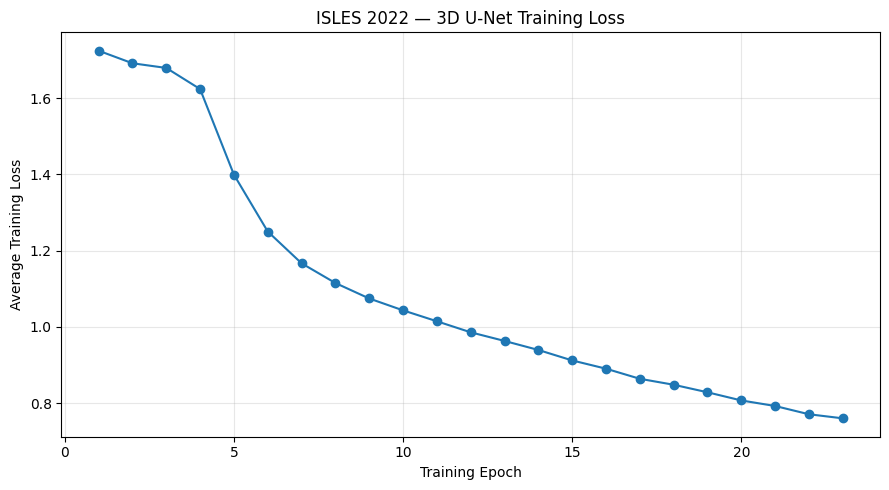


Extended training complete!
Total completed epochs: 23


In [33]:

# ============================================================
# STEP 11B: CONTINUE TRAINING FOR 20 MORE EPOCHS
# ============================================================

import torch
import json
import time
import os
import matplotlib.pyplot as plt

from pathlib import Path
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. DEFINE TRAINING SETTINGS
# ------------------------------------------------------------

# The original training run completed 3 epochs.
# We will continue through epoch 23.
START_EPOCH = 3
END_EPOCH = 23

# Checkpoints will be saved to persistent Google Drive.
CHECKPOINT_DIR = PROJECT_DIR / "models"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

checkpoint_path = CHECKPOINT_DIR / "checkpoint_latest.pt"

# ------------------------------------------------------------
# 2. RESTORE THE LATEST CHECKPOINT
# ------------------------------------------------------------

# Loading the saved checkpoint ensures that training
# resumes from the saved model and optimizer states,
# rather than depending on the current notebook memory.

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

# Restore learned neural network weights.
model.load_state_dict(
    checkpoint["model_state_dict"]
)

# Restore AdamW optimizer statistics.
optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

# Recover the previous training history.
training_history = checkpoint["training_history"]

# Read the actual saved epoch number.
completed_epochs = int(checkpoint["epoch"])

print("Restored checkpoint from epoch:", completed_epochs)

# Confirm we're starting from the expected point.
assert completed_epochs >= START_EPOCH, (
    "Checkpoint is older than expected."
)

# ------------------------------------------------------------
# 3. CONTINUE TRAINING
# ------------------------------------------------------------

for epoch in range(completed_epochs, END_EPOCH):

    # Put the model into training mode.
    model.train()

    epoch_loss = 0.0
    epoch_start = time.perf_counter()

    progress_bar = tqdm(
        extended_train_loader,
        desc=f"Epoch {epoch + 1}/{END_EPOCH}"
    )

    for batch in progress_bar:

        # Transfer MRI patches and masks to GPU.
        images = batch["image"].to(
            device,
            non_blocking=True
        )

        labels = batch["label"].to(
            device,
            non_blocking=True
        )

        # Clear gradients from the previous update.
        optimizer.zero_grad(set_to_none=True)

        # Forward pass: predict infarct segmentations.
        predictions = model(images)

        # Compare predictions with expert masks.
        loss = loss_function(predictions, labels)

        # Stop if the loss becomes NaN or infinite.
        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite loss at epoch {epoch + 1}"
            )

        # Backpropagation: calculate gradients.
        loss.backward()

        # Update the model's parameters.
        optimizer.step()

        # Accumulate training loss.
        epoch_loss += loss.item()

        # Update the progress bar.
        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    # --------------------------------------------------------
    # 4. RECORD EPOCH RESULTS
    # --------------------------------------------------------

    average_loss = (
        epoch_loss / len(extended_train_loader)
    )

    elapsed_minutes = (
        time.perf_counter() - epoch_start
    ) / 60

    training_history.append({
        "epoch": epoch + 1,
        "train_loss": average_loss,
        "duration_minutes": elapsed_minutes
    })

    print(
        f"\nEpoch {epoch + 1}/{END_EPOCH} | "
        f"Average loss: {average_loss:.4f} | "
        f"Time: {elapsed_minutes:.2f} min"
    )

    # --------------------------------------------------------
    # 5. SAVE CHECKPOINT AFTER EVERY EPOCH
    # --------------------------------------------------------

    checkpoint = {
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "training_history": training_history
    }

    # Save to a temporary file before replacing
    # the latest completed checkpoint.
    temporary_path = (
        CHECKPOINT_DIR / "checkpoint_latest.tmp"
    )

    torch.save(checkpoint, temporary_path)

    # Replace the previous checkpoint only after
    # the new file has been written successfully.
    os.replace(
        temporary_path,
        checkpoint_path
    )

    # Also save training history as JSON.
    history_path = (
        CHECKPOINT_DIR / "training_history.json"
    )

    with open(history_path, "w") as file:
        json.dump(
            training_history,
            file,
            indent=4
        )

    print("Checkpoint saved successfully.")

# ------------------------------------------------------------
# 6. PLOT TRAINING LOSS
# ------------------------------------------------------------

epochs = [
    entry["epoch"]
    for entry in training_history
]

losses = [
    entry["train_loss"]
    for entry in training_history
]

plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    losses,
    marker="o"
)

plt.xlabel("Training Epoch")
plt.ylabel("Average Training Loss")
plt.title("ISLES 2022 — 3D U-Net Training Loss")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nExtended training complete!")
print("Total completed epochs:", training_history[-1]["epoch"])


In [34]:

# ============================================================
# STEP 12: FULL VALIDATION OF THE TRAINED 3D U-NET
# ============================================================

import torch
import numpy as np
import pandas as pd

from monai.inferers import sliding_window_inference
from pathlib import Path
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. PREPARE VALIDATION
# ------------------------------------------------------------

# Put the trained model into evaluation mode.
model.eval()

# Store one row of results per validation patient.
validation_results = []

# Use the same threshold as our initial evaluation.
THRESHOLD = 0.5

# ------------------------------------------------------------
# 2. EVALUATE EACH HELD-OUT PATIENT
# ------------------------------------------------------------

for patient_id in tqdm(
    val_ids,
    desc="Validating patients"
):

    # Load the patient's cached, preprocessed MRI.
    patient_data = torch.load(
        LOCAL_CACHE_DIR / f"{patient_id}.pt",
        map_location="cpu",
        weights_only=True
    )

    # Image shape: (3, X, Y, Z)
    image = patient_data["image"]

    # Expert mask shape: (1, X, Y, Z)
    expert_mask = patient_data["label"]

    # Add batch dimension and transfer MRI to GPU.
    input_image = image.unsqueeze(0).to(device)

    # --------------------------------------------------------
    # 3. PREDICT THE FULL MRI VOLUME
    # --------------------------------------------------------

    with torch.no_grad():

        logits = sliding_window_inference(
            inputs=input_image,
            roi_size=(64, 64, 32),
            sw_batch_size=1,
            predictor=model,
            overlap=0.25,

            # Run individual patches on GPU but assemble
            # the final prediction on CPU to save VRAM.
            sw_device=device,
            device=torch.device("cpu")
        )

        # Convert logits to probabilities, then binary mask.
        prediction = (
            torch.sigmoid(logits) >= THRESHOLD
        ).squeeze().numpy()

    # Convert expert annotations to a binary array.
    ground_truth = (
        expert_mask.squeeze().numpy() > 0
    )

    # --------------------------------------------------------
    # 4. CALCULATE SEGMENTATION METRICS
    # --------------------------------------------------------

    predicted_voxels = int(prediction.sum())
    expert_voxels = int(ground_truth.sum())

    intersection = int(
        np.logical_and(
            prediction,
            ground_truth
        ).sum()
    )

    denominator = predicted_voxels + expert_voxels

    # For empty/empty masks, Dice is defined as 1.
    # If only one mask is empty, Dice is 0.
    dice = (
        2 * intersection / denominator
        if denominator > 0
        else 1.0
    )

    # Save patient-level results.
    validation_results.append({
        "patient_id": patient_id,
        "dice": dice,
        "expert_voxels": expert_voxels,
        "predicted_voxels": predicted_voxels,
        "intersection_voxels": intersection
    })

# ------------------------------------------------------------
# 5. SUMMARIZE RESULTS ACROSS ALL PATIENTS
# ------------------------------------------------------------

results_df = pd.DataFrame(validation_results)

print("\n" + "=" * 50)
print("FULL VALIDATION RESULTS")
print("=" * 50)

print("Patients evaluated:", len(results_df))

print(
    "Mean Dice:",
    round(results_df["dice"].mean(), 4)
)

print(
    "Median Dice:",
    round(results_df["dice"].median(), 4)
)

print(
    "Best Dice:",
    round(results_df["dice"].max(), 4)
)

print(
    "Worst Dice:",
    round(results_df["dice"].min(), 4)
)

print(
    "Cases with no predicted lesion:",
    int((results_df["predicted_voxels"] == 0).sum())
)

print(
    "Cases with no expert lesion:",
    int((results_df["expert_voxels"] == 0).sum())
)

# ------------------------------------------------------------
# 6. SAVE VALIDATION RESULTS TO GOOGLE DRIVE
# ------------------------------------------------------------

results_dir = PROJECT_DIR / "results"
results_dir.mkdir(parents=True, exist_ok=True)

results_path = results_dir / "validation_epoch23.csv"

results_df.to_csv(
    results_path,
    index=False
)

print("\nSaved validation results to:", results_path)

# ------------------------------------------------------------
# 7. DISPLAY PATIENT-LEVEL RESULTS
# ------------------------------------------------------------

print("\nBest five cases:")
print(
    results_df.nlargest(5, "dice").to_string(index=False)
)

print("\nWorst five cases:")
print(
    results_df.nsmallest(5, "dice").to_string(index=False)
)

print("\nValidation complete!")


Validating patients:   0%|          | 0/37 [00:00<?, ?it/s]


FULL VALIDATION RESULTS
Patients evaluated: 37
Mean Dice: 0.027
Median Dice: 0.0
Best Dice: 1.0
Worst Dice: 0.0
Cases with no predicted lesion: 37
Cases with no expert lesion: 1

Saved validation results to: /content/drive/MyDrive/ISLES2022_Project/results/validation_epoch23.csv

Best five cases:
        patient_id  dice  expert_voxels  predicted_voxels  intersection_voxels
sub-strokecase0170   1.0              0                 0                    0
sub-strokecase0059   0.0             87                 0                    0
sub-strokecase0193   0.0           1842                 0                    0
sub-strokecase0018   0.0            133                 0                    0
sub-strokecase0050   0.0           1925                 0                    0

Worst five cases:
        patient_id  dice  expert_voxels  predicted_voxels  intersection_voxels
sub-strokecase0059   0.0             87                 0                    0
sub-strokecase0193   0.0           1842           

In [35]:

# ============================================================
# STEP 13: CHECK WHETHER THE MODEL RECOGNIZES LESION VOXELS
# ============================================================

import torch
import numpy as np
from monai.inferers import sliding_window_inference

# ------------------------------------------------------------
# 1. LOAD A VALIDATION PATIENT WITH A KNOWN INFARCT
# ------------------------------------------------------------

patient_id = "sub-strokecase0193"

patient_data = torch.load(
    LOCAL_CACHE_DIR / f"{patient_id}.pt",
    map_location="cpu",
    weights_only=True
)

image = patient_data["image"]
expert_mask = patient_data["label"]

# Convert the expert annotation into a Boolean array.
ground_truth = expert_mask.squeeze().numpy() > 0

# ------------------------------------------------------------
# 2. GENERATE THE MODEL'S PROBABILITY MAP
# ------------------------------------------------------------

model.eval()

with torch.no_grad():

    logits = sliding_window_inference(
        inputs=image.unsqueeze(0).to(device),
        roi_size=(64, 64, 32),
        sw_batch_size=1,
        predictor=model,
        overlap=0.25,
        sw_device=device,
        device=torch.device("cpu")
    )

    # Sigmoid converts raw model outputs to probabilities.
    probability_map = (
        torch.sigmoid(logits)
        .squeeze()
        .numpy()
    )

# ------------------------------------------------------------
# 3. COMPARE LESION AND BACKGROUND PROBABILITIES
# ------------------------------------------------------------

# Probabilities inside the expert-annotated infarct.
lesion_probabilities = probability_map[ground_truth]

# Probabilities outside the expert-annotated infarct.
background_probabilities = probability_map[~ground_truth]

print("Patient:", patient_id)
print("Expert lesion voxels:", int(ground_truth.sum()))

print("\nLESION VOXELS")
print("Mean probability:", lesion_probabilities.mean())
print("Maximum probability:", lesion_probabilities.max())

print("\nBACKGROUND VOXELS")
print("Mean probability:", background_probabilities.mean())
print("Maximum probability:", background_probabilities.max())

# ------------------------------------------------------------
# 4. CHECK MORE PERMISSIVE THRESHOLDS
# ------------------------------------------------------------

print("\nThreshold | Predicted voxels | Dice")
print("-" * 42)

for threshold in [0.05, 0.10, 0.20, 0.30, 0.40, 0.50]:

    prediction = probability_map >= threshold

    predicted_voxels = int(prediction.sum())
    expert_voxels = int(ground_truth.sum())

    intersection = int(
        np.logical_and(prediction, ground_truth).sum()
    )

    denominator = predicted_voxels + expert_voxels

    dice = (
        2 * intersection / denominator
        if denominator > 0
        else 1.0
    )

    print(
        f"{threshold:8.2f} | "
        f"{predicted_voxels:16d} | "
        f"{dice:.4f}"
    )

print("\nDiagnostic complete!")


Patient: sub-strokecase0193
Expert lesion voxels: 1842

LESION VOXELS
Mean probability: 0.40705028
Maximum probability: 0.48515266

BACKGROUND VOXELS
Mean probability: 0.0010149672
Maximum probability: 0.47785246

Threshold | Predicted voxels | Dice
------------------------------------------
    0.05 |             4839 | 0.5347
    0.10 |             4148 | 0.5893
    0.20 |             3324 | 0.6593
    0.30 |             2696 | 0.7162
    0.40 |             1906 | 0.7631
    0.50 |                0 | 0.0000

Diagnostic complete!


In [36]:

# ============================================================
# STEP 14: FIND A SEGMENTATION THRESHOLD
# USING ALL 37 VALIDATION PATIENTS
# ============================================================

import torch
import numpy as np
import pandas as pd

from monai.inferers import sliding_window_inference
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. DEFINE THRESHOLDS TO EVALUATE
# ------------------------------------------------------------

# These thresholds convert model probabilities
# into binary lesion segmentation masks.

thresholds = [
    0.05,
    0.10,
    0.15,
    0.20,
    0.25,
    0.30,
    0.35,
    0.40,
    0.45,
    0.50
]

# Store patient-level results for each threshold.
all_results = []

# Put the model into evaluation mode.
model.eval()

# ------------------------------------------------------------
# 2. GENERATE ONE PROBABILITY MAP PER PATIENT
# ------------------------------------------------------------

# We only need to run the neural network once per
# patient. Then we can apply every threshold to
# the same probability map.

for patient_id in tqdm(
    val_ids,
    desc="Evaluating thresholds"
):

    # Load preprocessed MRI and expert mask.
    patient_data = torch.load(
        LOCAL_CACHE_DIR / f"{patient_id}.pt",
        map_location="cpu",
        weights_only=True
    )

    image = patient_data["image"]

    ground_truth = (
        patient_data["label"]
        .squeeze()
        .numpy() > 0
    )

    expert_voxels = int(ground_truth.sum())

    # Predict the full MRI volume.
    with torch.no_grad():

        logits = sliding_window_inference(
            inputs=image.unsqueeze(0).to(device),
            roi_size=(64, 64, 32),
            sw_batch_size=1,
            predictor=model,
            overlap=0.25,
            sw_device=device,
            device=torch.device("cpu")
        )

        probability_map = (
            torch.sigmoid(logits)
            .squeeze()
            .numpy()
        )

    # --------------------------------------------------------
    # 3. CALCULATE DICE FOR EACH THRESHOLD
    # --------------------------------------------------------

    for threshold in thresholds:

        prediction = probability_map >= threshold

        predicted_voxels = int(prediction.sum())

        intersection = int(
            np.logical_and(
                prediction,
                ground_truth
            ).sum()
        )

        denominator = predicted_voxels + expert_voxels

        dice = (
            2 * intersection / denominator
            if denominator > 0
            else 1.0
        )

        all_results.append({
            "patient_id": patient_id,
            "threshold": threshold,
            "dice": dice,
            "expert_voxels": expert_voxels,
            "predicted_voxels": predicted_voxels
        })

# ------------------------------------------------------------
# 4. SUMMARIZE PERFORMANCE BY THRESHOLD
# ------------------------------------------------------------

threshold_df = pd.DataFrame(all_results)

# For threshold selection, focus on patients with
# expert-confirmed infarcts. Empty-mask cases will
# be evaluated separately.
lesion_df = threshold_df[
    threshold_df["expert_voxels"] > 0
]

summary = (
    lesion_df
    .groupby("threshold")
    .agg(
        mean_dice=("dice", "mean"),
        median_dice=("dice", "median"),
        zero_predictions=(
            "predicted_voxels",
            lambda x: int((x == 0).sum())
        )
    )
    .reset_index()
)

print("\nVALIDATION THRESHOLD COMPARISON")
print("=" * 55)

print(summary.to_string(index=False))

# ------------------------------------------------------------
# 5. IDENTIFY THE BEST VALIDATION THRESHOLD
# ------------------------------------------------------------

best_row = summary.loc[
    summary["mean_dice"].idxmax()
]

best_threshold = float(best_row["threshold"])

print("\nBest validation threshold:", best_threshold)

print(
    "Mean Dice at best threshold:",
    round(float(best_row["mean_dice"]), 4)
)

print(
    "Median Dice at best threshold:",
    round(float(best_row["median_dice"]), 4)
)

# ------------------------------------------------------------
# 6. SAVE RESULTS TO GOOGLE DRIVE
# ------------------------------------------------------------

results_dir = PROJECT_DIR / "results"
results_dir.mkdir(parents=True, exist_ok=True)

threshold_df.to_csv(
    results_dir / "validation_threshold_details.csv",
    index=False
)

summary.to_csv(
    results_dir / "validation_threshold_summary.csv",
    index=False
)

print("\nThreshold evaluation complete!")

# Bind the selected threshold to the exact epoch-23 weights evaluated above.
latest_path = PROJECT_DIR / "models" / "checkpoint_latest.pt"
threshold_checkpoint = torch.load(latest_path, map_location="cpu", weights_only=True)
current_state = model.state_dict()
saved_state = threshold_checkpoint["model_state_dict"]
if int(threshold_checkpoint["epoch"]) != 23 or set(current_state) != set(saved_state):
    raise ValueError("Threshold selection requires the current epoch-23 checkpoint.")
if not all(torch.equal(value.cpu(), saved_state[key]) for key, value in current_state.items()):
    raise ValueError("Threshold selection model differs from the saved checkpoint.")
if "selection" in threshold_checkpoint:
    raise ValueError("Selection is already initialized; resume Step 16 without retuning.")
threshold_checkpoint["validation_threshold"] = best_threshold
threshold_tmp = latest_path.with_suffix(".tmp")
torch.save(threshold_checkpoint, threshold_tmp)
threshold_tmp.replace(latest_path)


Evaluating thresholds:   0%|          | 0/37 [00:00<?, ?it/s]


VALIDATION THRESHOLD COMPARISON
 threshold  mean_dice  median_dice  zero_predictions
      0.05   0.463843     0.450544                 0
      0.10   0.492803     0.512238                 0
      0.15   0.504100     0.564660                 1
      0.20   0.515741     0.593855                 1
      0.25   0.521933     0.622956                 2
      0.30   0.520222     0.643718                 4
      0.35   0.513303     0.654332                 4
      0.40   0.478537     0.594938                 4
      0.45   0.282863     0.253205                 7
      0.50   0.000000     0.000000                36

Best validation threshold: 0.25
Mean Dice at best threshold: 0.5219
Median Dice at best threshold: 0.623

Threshold evaluation complete!


Patient: sub-strokecase0193
Selected slice: 16


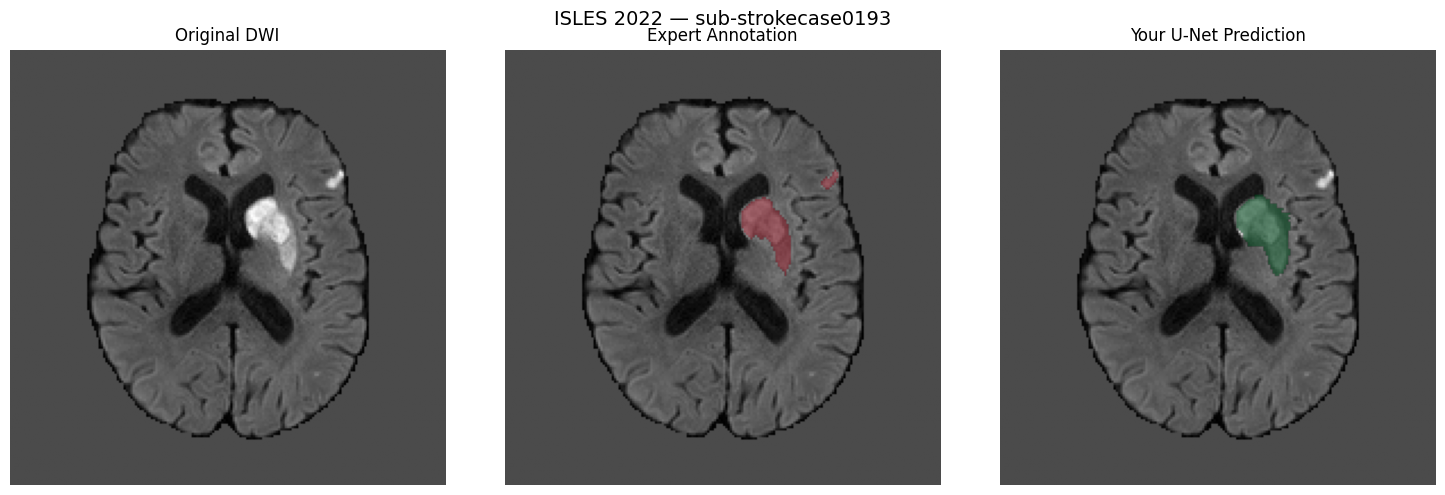


Segmentation visualization complete!


In [37]:

# ============================================================
# STEP 15: VISUALIZE EXPERT VS AI STROKE SEGMENTATION
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt

from monai.inferers import sliding_window_inference

# ------------------------------------------------------------
# 1. SELECT A VALIDATION PATIENT
# ------------------------------------------------------------

# This is the patient we previously examined.
# You can change this ID to another validation patient.
patient_id = "sub-strokecase0193"

patient_data = torch.load(
    LOCAL_CACHE_DIR / f"{patient_id}.pt",
    map_location="cpu",
    weights_only=True
)

image = patient_data["image"]
expert_mask = patient_data["label"]

# ------------------------------------------------------------
# 2. GENERATE THE AI SEGMENTATION
# ------------------------------------------------------------

model.eval()

with torch.no_grad():

    logits = sliding_window_inference(
        inputs=image.unsqueeze(0).to(device),
        roi_size=(64, 64, 32),
        sw_batch_size=1,
        predictor=model,
        overlap=0.25,
        sw_device=device,
        device=torch.device("cpu")
    )

    # Use the threshold selected on validation data.
    predicted_mask = (
        torch.sigmoid(logits) >= best_threshold
    ).squeeze().numpy()

# ------------------------------------------------------------
# 3. EXTRACT THE MRI AND EXPERT ANNOTATIONS
# ------------------------------------------------------------

# Channel 0 corresponds to the DWI MRI.
dwi = image[0].numpy()

# Convert expert segmentation to a Boolean mask.
ground_truth = expert_mask.squeeze().numpy() > 0

# ------------------------------------------------------------
# 4. CHOOSE A SLICE CONTAINING THE MOST LESION VOXELS
# ------------------------------------------------------------

# Sum expert lesion voxels along the first two axes.
# This gives the lesion area in each axial slice.
lesion_voxels_per_slice = ground_truth.sum(axis=(0, 1))

# Select the slice with the largest annotated lesion.
slice_index = int(np.argmax(lesion_voxels_per_slice))

print("Patient:", patient_id)
print("Selected slice:", slice_index)

# ------------------------------------------------------------
# 5. PREPARE THREE PANELS
# ------------------------------------------------------------

# Rotate the images consistently for display.
dwi_slice = np.rot90(dwi[:, :, slice_index])

expert_slice = np.rot90(
    ground_truth[:, :, slice_index]
)

prediction_slice = np.rot90(
    predicted_mask[:, :, slice_index]
)

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5)
)

# Panel 1: Original DWI.
axes[0].imshow(
    dwi_slice,
    cmap="gray"
)

axes[0].set_title("Original DWI")

# Panel 2: DWI with expert segmentation.
axes[1].imshow(
    dwi_slice,
    cmap="gray"
)

axes[1].imshow(
    np.ma.masked_where(
        ~expert_slice,
        expert_slice
    ),
    cmap="Reds",
    alpha=0.6,
    vmin=0,
    vmax=1
)

axes[1].set_title("Expert Annotation")

# Panel 3: DWI with AI prediction.
axes[2].imshow(
    dwi_slice,
    cmap="gray"
)

axes[2].imshow(
    np.ma.masked_where(
        ~prediction_slice,
        prediction_slice
    ),
    cmap="Greens",
    alpha=0.6,
    vmin=0,
    vmax=1
)

axes[2].set_title("Your U-Net Prediction")

# Remove axis labels for a cleaner presentation.
for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"ISLES 2022 — {patient_id}",
    fontsize=14
)

plt.tight_layout()
plt.show()

print("\nSegmentation visualization complete!")


In [38]:

# ============================================================
# STEP 16: CONTINUE TRAINING FROM EPOCH 23 TO EPOCH 43
# WITH VALIDATION EVERY 5 EPOCHS
# ============================================================

import torch
import numpy as np
import pandas as pd
import json
import os
import time

from pathlib import Path
from tqdm.auto import tqdm
from monai.inferers import sliding_window_inference

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

END_EPOCH = 43
VALIDATE_EVERY = 5
# Fresh selection uses the threshold persisted by Step 14; resume uses checkpoint metadata.
VALIDATION_THRESHOLD = None

MODELS_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

latest_path = MODELS_DIR / "checkpoint_latest.pt"
baseline_path = MODELS_DIR / "checkpoint_epoch23.pt"
best_path = MODELS_DIR / "checkpoint_best_validation.pt"

metrics_path = RESULTS_DIR / "extended_validation_history.csv"

# ------------------------------------------------------------
# 2. LOAD THE MOST RECENT TRAINING CHECKPOINT
# ------------------------------------------------------------

checkpoint = torch.load(
    latest_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

completed_epochs = int(checkpoint["epoch"])
training_history = checkpoint["training_history"]

print("Resuming from epoch:", completed_epochs)

# ------------------------------------------------------------
# 3. DEFINE FULL-VOLUME VALIDATION
# ------------------------------------------------------------

def evaluate_validation(model, patient_ids, threshold=0.25):
    """
    Evaluate segmentation Dice across held-out patients.

    Returns:
        Mean Dice among lesion-positive patients.
        Median Dice among lesion-positive patients.
        Number of lesion-positive cases with no prediction.
        Number of lesion-negative cases with false positives.
    """

    model.eval()

    patient_results = []

    with torch.no_grad():

        for patient_id in patient_ids:

            # Load one preprocessed validation MRI.
            data = torch.load(
                LOCAL_CACHE_DIR / f"{patient_id}.pt",
                map_location="cpu",
                weights_only=True
            )

            image = data["image"]

            # Convert expert mask to Boolean values.
            expert = data["label"].squeeze().numpy() > 0

            # Perform full-volume segmentation.
            logits = sliding_window_inference(
                inputs=image.unsqueeze(0).to(device),
                roi_size=(64, 64, 32),
                sw_batch_size=1,
                predictor=model,
                overlap=0.25,
                sw_device=device,
                device=torch.device("cpu")
            )

            # Apply the fixed validation threshold.
            prediction = (
                torch.sigmoid(logits).squeeze().numpy()
                >= threshold
            )

            expert_count = int(expert.sum())
            prediction_count = int(prediction.sum())

            intersection = int(
                np.logical_and(expert, prediction).sum()
            )

            denominator = expert_count + prediction_count

            dice = (
                2 * intersection / denominator
                if denominator > 0
                else 1.0
            )

            patient_results.append({
                "patient_id": patient_id,
                "dice": dice,
                "expert_voxels": expert_count,
                "predicted_voxels": prediction_count
            })

    df = pd.DataFrame(patient_results)

    # Select lesion-positive patients for the primary
    # Dice metric, consistent with our earlier results.
    positive = df[df["expert_voxels"] > 0]

    # Count missed lesion-positive patients.
    missed = int(
        (positive["predicted_voxels"] == 0).sum()
    )

    # Count false positives in lesion-negative patients.
    negative = df[df["expert_voxels"] == 0]

    false_positive_cases = int(
        (negative["predicted_voxels"] > 0).sum()
    )

    return {
        "mean_dice": float(positive["dice"].mean()),
        "median_dice": float(positive["dice"].median()),
        "missed_cases": missed,
        "false_positive_negative_cases": false_positive_cases
    }

# ------------------------------------------------------------
# 4. RESTORE OR ESTABLISH THE BASELINE
# ------------------------------------------------------------

import hashlib
import inspect
import math
import uuid


def state_digest(state):
    """Identify weights independently of checkpoint serialization/device."""
    digest = hashlib.sha256()
    for key, value in sorted(state.items()):
        tensor = value.detach().cpu().contiguous()
        digest.update(key.encode())
        digest.update(str((str(tensor.dtype), tuple(tensor.shape))).encode())
        digest.update(tensor.reshape(-1).view(torch.uint8).numpy().tobytes())
    return digest.hexdigest()


def canonical_json_value(value):
    """Copy metadata into its stable JSON representation without dropping fields.

    AdamW betas are tuples in memory and lists after JSON decoding. Both are
    JSON arrays; canonicalize before hashing, writing and exact comparison.
    Unsupported objects/nonfinite numbers fail rather than become strings.
    """
    return json.loads(json.dumps(value, sort_keys=True, allow_nan=False))


def context_digest(context):
    # Keep the existing sorted-JSON byte encoding and checkpoint/path digests.
    return hashlib.sha256(
        json.dumps(canonical_json_value(context), sort_keys=True, allow_nan=False).encode()
    ).hexdigest()


def validate_selection(checkpoint, context, expected_run_id=None):
    selection = checkpoint.get("selection")
    if not selection or selection["context_hash"] != context_digest(context):
        raise ValueError("Missing or mismatched selection provenance; restore epoch 23 and rerun Step 14.")
    if selection["weights_hash"] != state_digest(checkpoint["model_state_dict"]):
        raise ValueError("Checkpoint weights do not match selection metadata.")
    if expected_run_id is not None and selection["run_id"] != expected_run_id:
        raise ValueError("Checkpoint belongs to another selection run.")
    threshold = float(selection["threshold"])
    if not math.isfinite(threshold) or not 0 <= threshold <= 1:
        raise ValueError("Invalid checkpoint threshold.")
    return selection


def establish_selection(checkpoint, context, evaluate, previous_best=None):
    """Measure this run's weights; CSVs and historical scores never select models.

    A legacy epoch-23 checkpoint can start a new selection run after Step 14.
    Later legacy checkpoints cannot establish lineage and must not be adopted.
    """
    if "selection" not in checkpoint:
        if int(checkpoint["epoch"]) != 23:
            raise ValueError("Legacy resume needs the epoch-23 checkpoint and Step 14.")
        if "validation_threshold" not in checkpoint:
            raise ValueError("Rerun Step 14 on the epoch-23 weights before starting selection.")
        threshold = float(checkpoint["validation_threshold"])
        if not math.isfinite(threshold) or not 0 <= threshold <= 1:
            raise ValueError("Invalid validation-selected threshold.")
        selection = {
            "run_id": str(uuid.uuid4()),
            "context_hash": context_digest(context),
            "threshold": threshold,
            "history": [],
        }
        best = checkpoint
    else:
        selection = dict(validate_selection(checkpoint, context))
        selection["history"] = list(selection["history"])
        if previous_best is None:
            raise ValueError("Best checkpoint is missing; restore it before resuming.")
        best_selection = validate_selection(previous_best, context)
        if (best_selection["run_id"] != selection["run_id"]
                or best_selection["threshold"] != selection["threshold"]
                or int(previous_best["epoch"]) > int(checkpoint["epoch"])):
            raise ValueError("Best checkpoint belongs to another selection run or threshold.")
        best = previous_best
    metrics = evaluate(best, selection["threshold"])
    if not math.isfinite(metrics["mean_dice"]):
        raise ValueError("Validation mean Dice must be finite.")
    # Replace this epoch's record with a measurement of its actual weights.
    selection["history"] = [row for row in selection["history"] if row["epoch"] != best["epoch"]]
    selection["history"].append({"epoch": int(best["epoch"]), **metrics})
    selection["history"].sort(key=lambda row: row["epoch"])
    best = dict(best)
    best["selection"] = {**selection, "weights_hash": state_digest(best["model_state_dict"])}
    checkpoint = dict(checkpoint)
    checkpoint["selection"] = {**selection, "weights_hash": state_digest(checkpoint["model_state_dict"])}
    return checkpoint, best, metrics


def save_atomic(checkpoint, path):
    temporary = path.with_suffix(".tmp")
    torch.save(checkpoint, temporary)
    os.replace(temporary, path)


# Fingerprint the actual cached tensors, split order, preprocessing/sampling source,
# architecture and training settings. Changed cache content rejects selection resume.
cache_digest = hashlib.sha256()
for patient_id in train_ids + val_ids:
    cache_digest.update(patient_id.encode())
    with open(LOCAL_CACHE_DIR / f"{patient_id}.pt", "rb") as cache_file:
        for chunk in iter(lambda: cache_file.read(8 * 1024 * 1024), b""):
            cache_digest.update(chunk)
selection_context = {
    "splits": {"train": train_ids, "validation": val_ids, "test": test_ids},
    "cache_sha256": cache_digest.hexdigest(),
    "preprocessing_source": inspect.getsource(preprocess_patient) + inspect.getsource(normalize_mri),
    "sampling_source": inspect.getsource(extract_patch),
    "architecture": str(model),
    "optimizer": [{key: value for key, value in group.items() if key != "params"}
                  for group in optimizer.param_groups],
    "loss": str(loss_function),
    "loss_settings": {
        name: {key: value for key, value in vars(component).items()
               if not key.startswith("_") and key != "training"
               and isinstance(value, (str, int, float, bool, type(None)))}
        for name, component in loss_function.named_modules()
    },
    "evaluation_source": inspect.getsource(evaluate_validation),
    "patch_size": list(PATCH_SIZE),
    "patches_per_patient": extended_train_dataset.patches_per_patient,
    "batch_size": extended_train_loader.batch_size,
    "roi_size": [64, 64, 32], "overlap": 0.25, "sw_batch_size": 1,
    "validation_every": VALIDATE_EVERY,
    "torch_version": str(torch.__version__),
    "monai_version": __import__("monai").__version__,
}


def measure_checkpoint(candidate, threshold):
    model.load_state_dict(candidate["model_state_dict"])
    return evaluate_validation(model, val_ids, threshold=threshold)


# Legacy artifacts are ignored only when establishing a new epoch-23 selection.
# A resumed selection requires a matching best checkpoint; never guess its lineage.
previous_best = None
if "selection" in checkpoint and best_path.exists():
    previous_best = torch.load(best_path, map_location="cpu", weights_only=True)
checkpoint, best_checkpoint, baseline_metrics = establish_selection(
    checkpoint, selection_context, measure_checkpoint, previous_best
)
model.load_state_dict(checkpoint["model_state_dict"])
VALIDATION_THRESHOLD = checkpoint["selection"]["threshold"]
selection_run_id = checkpoint["selection"]["run_id"]
validation_history = checkpoint["selection"]["history"]
best_dice = baseline_metrics["mean_dice"]
best_epoch = int(best_checkpoint["epoch"])
save_atomic(best_checkpoint, best_path)
save_atomic(checkpoint, latest_path)
if completed_epochs == 23:
    save_atomic(checkpoint, baseline_path)
pd.DataFrame(validation_history).to_csv(metrics_path, index=False)

print(f"Best recorded validation Dice: {best_dice:.4f}")
print(f"Best recorded epoch: {best_epoch}")

# ------------------------------------------------------------
# 5. CONTINUE TRAINING
# ------------------------------------------------------------

for epoch in range(completed_epochs, END_EPOCH):

    model.train()

    epoch_loss = 0.0
    epoch_start = time.perf_counter()

    progress = tqdm(
        extended_train_loader,
        desc=f"Epoch {epoch + 1}/{END_EPOCH}"
    )

    for batch in progress:

        images = batch["image"].to(
            device,
            non_blocking=True
        )

        labels = batch["label"].to(
            device,
            non_blocking=True
        )

        # Forward pass.
        optimizer.zero_grad(set_to_none=True)
        predictions = model(images)

        # Calculate combined Dice + cross-entropy loss.
        loss = loss_function(predictions, labels)

        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite training loss.")

        # Backpropagation and weight update.
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

        progress.set_postfix(loss=f"{loss.item():.4f}")

    average_loss = epoch_loss / len(extended_train_loader)

    elapsed = (
        time.perf_counter() - epoch_start
    ) / 60

    training_history.append({
        "epoch": epoch + 1,
        "train_loss": average_loss,
        "duration_minutes": elapsed
    })

    print(
        f"\nEpoch {epoch + 1}/{END_EPOCH} | "
        f"Training loss: {average_loss:.4f}"
    )

    # --------------------------------------------------------
    # 6. SAVE A RESUMABLE CHECKPOINT EVERY EPOCH
    # --------------------------------------------------------

    current_checkpoint = {
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "training_history": training_history
    }

    current_checkpoint["selection"] = {
        **checkpoint["selection"],
        "history": validation_history,
        "weights_hash": state_digest(current_checkpoint["model_state_dict"]),
    }

    # --------------------------------------------------------
    # 7. VALIDATE EVERY 5 EPOCHS AFTER EPOCH 23
    # --------------------------------------------------------

    current_epoch = epoch + 1

    if (current_epoch - 23) % VALIDATE_EVERY == 0:

        metrics = evaluate_validation(
            model,
            val_ids,
            threshold=VALIDATION_THRESHOLD
        )

        if not math.isfinite(metrics["mean_dice"]):
            raise ValueError("Validation mean Dice must be finite.")
        validation_history.append({
            "epoch": current_epoch,
            **metrics
        })

        print("\n" + "=" * 45)
        print(f"VALIDATION — EPOCH {current_epoch}")
        print("=" * 45)

        print(f"Mean Dice: {metrics['mean_dice']:.4f}")
        print(f"Median Dice: {metrics['median_dice']:.4f}")
        print(f"Missed cases: {metrics['missed_cases']}")
        print(
            "False-positive lesion-negative cases:",
            metrics["false_positive_negative_cases"]
        )

        # Save a new best checkpoint only if mean
        # validation Dice improves.
        if metrics["mean_dice"] > best_dice:

            best_dice = metrics["mean_dice"]
            best_epoch = current_epoch

            save_atomic(current_checkpoint, best_path)

            print("NEW BEST MODEL SAVED!")

        # Save validation history to Google Drive.
        pd.DataFrame(validation_history).to_csv(
            metrics_path,
            index=False
        )

        print(
            f"Best so far: epoch {best_epoch}, "
            f"Dice {best_dice:.4f}"
        )

    # Save after validation so resume metadata and weights share one transaction.
    save_atomic(current_checkpoint, latest_path)
    checkpoint = current_checkpoint

# ------------------------------------------------------------
# 8. DISPLAY FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 50)
print("EXTENDED TRAINING COMPLETE")
print("=" * 50)

print("Best epoch:", best_epoch)
print("Best validation mean Dice:", round(best_dice, 4))
print("Best model saved to:", best_path)

print("\nValidation history:")
print(
    pd.DataFrame(validation_history).to_string(index=False)
)

# Test artifacts are bound to their exact selected weights and experiment context.
# These helpers stay in the notebook so Colab does not need an installed checkout.
import io
import importlib.metadata
import platform
import re


def test_artifact_provenance(candidate, context, run_id, patient_ids):
    context = canonical_json_value(context)
    selection = validate_selection(candidate, context, run_id)
    if list(patient_ids) != context["splits"]["test"]:
        raise ValueError("Test artifact cohort differs from the saved split.")
    if len(patient_ids) != len(set(patient_ids)):
        raise ValueError("Test artifact patient IDs must be unique.")
    source = inspect.getsource(preprocess_patient) + inspect.getsource(normalize_mri)
    if source != context["preprocessing_source"]:
        raise ValueError("Current preprocessing differs from the selected checkpoint context.")
    if not re.fullmatch(r"[A-Za-z0-9_-]+", run_id):
        raise ValueError("Invalid artifact run ID.")
    identity = {
        "run_id": selection["run_id"],
        "epoch": int(candidate["epoch"]),
        "weights_sha256": state_digest(candidate["model_state_dict"]),
        "threshold": float(selection["threshold"]),
        "context_sha256": selection["context_hash"],
    }
    return {
        "schema_version": 1,
        **identity,
        # Canonical digest of selected weights plus epoch/run/threshold/context.
        "checkpoint_digest": context_digest(identity),
        "context": context,
        "patient_ids": list(patient_ids),
        "environment": {
            "python": platform.python_version(),
            "platform": platform.platform(),
            "torch_cuda_version": torch.version.cuda,
            "cuda_available": torch.cuda.is_available(),
            "packages": {name: importlib.metadata.version(name) for name in
                         ("torch", "monai", "numpy", "nibabel", "scipy", "pandas", "matplotlib")},
        },
    }


def test_artifact_directory(project_dir, provenance):
    provenance = canonical_json_value(provenance)
    # The full identity digest also distinguishes environment/configuration changes.
    return (project_dir / "results" / "runs" / provenance["run_id"] /
            f"epoch{provenance['epoch']}-{context_digest(provenance)}")


def write_artifact_manifest(path, provenance, source_manifest=None):
    provenance = canonical_json_value(provenance)
    manifest = {"provenance": provenance,
                "sha256": hashlib.sha256(path.read_bytes()).hexdigest()}
    if source_manifest is not None:
        if canonical_json_value(source_manifest["provenance"]) != provenance:
            raise ValueError("Figure source belongs to another experiment.")
        manifest["source_test_csv_sha256"] = source_manifest["sha256"]
    manifest_path = path.with_suffix(path.suffix + ".manifest.json")
    temporary = manifest_path.with_suffix(manifest_path.suffix + ".tmp")
    temporary.write_text(json.dumps(manifest, sort_keys=True, indent=2) + "\n")
    os.replace(temporary, manifest_path)
    return manifest


def read_test_artifact(project_dir, provenance):
    provenance = canonical_json_value(provenance)
    path = test_artifact_directory(project_dir, provenance) / "test.csv"
    manifest_path = path.with_suffix(".csv.manifest.json")
    if not path.exists() or not manifest_path.exists():
        raise ValueError("No provenance-bound test results; rerun Step 17 for this checkpoint.")
    manifest = json.loads(manifest_path.read_text())
    if canonical_json_value(manifest.get("provenance")) != provenance:
        raise ValueError("Test results belong to another run/checkpoint/threshold/split/configuration.")
    content = path.read_bytes()
    if hashlib.sha256(content).hexdigest() != manifest.get("sha256"):
        raise ValueError("Test results content does not match its manifest.")
    frame = pd.read_csv(io.BytesIO(content))
    if frame["patient_id"].tolist() != provenance["patient_ids"]:
        raise ValueError("Test results patient order/cohort differs from the recorded split.")
    return frame, manifest


def save_test_artifact(frame, project_dir, provenance):
    provenance = canonical_json_value(provenance)
    if frame["patient_id"].tolist() != provenance["patient_ids"]:
        raise ValueError("Cannot export results for a different test cohort.")
    path = test_artifact_directory(project_dir, provenance) / "test.csv"
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(".csv.tmp")
    frame.to_csv(temporary, index=False)
    os.replace(temporary, path)
    write_artifact_manifest(path, provenance)
    return path


def check_figure_metrics(prediction, expert, patient_row):
    # Reject metrics that differ from this figure's recomputed prediction.
    expert_count = int(expert.sum())
    predicted_count = int(prediction.sum())
    intersection = int(np.logical_and(expert, prediction).sum())
    denominator = expert_count + predicted_count
    dice = 2 * intersection / denominator if denominator else 1.0
    if (expert_count != int(patient_row["expert_voxels"])
            or predicted_count != int(patient_row["predicted_voxels"])
            or intersection != int(patient_row["intersection_voxels"])
            or not math.isclose(dice, float(patient_row["dice"]), rel_tol=1e-12, abs_tol=1e-12)):
        raise ValueError("Figure prediction disagrees with the provenance-bound test results.")



Resuming from epoch: 23
Epoch-23 baseline preserved.
Best recorded validation Dice: 0.5219
Best recorded epoch: 23


Epoch 24/43:   0%|          | 0/350 [00:00<?, ?it/s]


Epoch 24/43 | Training loss: 0.7436


Epoch 25/43:   0%|          | 0/350 [00:00<?, ?it/s]


Epoch 25/43 | Training loss: 0.7380


...


Epoch 41/43 | Training loss: 0.6234


Epoch 42/43:   0%|          | 0/350 [00:00<?, ?it/s]


Epoch 42/43 | Training loss: 0.6234


Epoch 43/43:   0%|          | 0/350 [00:00<?, ?it/s]


Epoch 43/43 | Training loss: 0.6299

VALIDATION — EPOCH 43
Mean Dice: 0.5991
Median Dice: 0.6578
Missed cases: 1
False-positive lesion-negative cases: 1
NEW BEST MODEL SAVED!
Best so far: epoch 43, Dice 0.5991

EXTENDED TRAINING COMPLETE
Best epoch: 43
Best validation mean Dice: 0.5991
Best model saved to: /content/drive/MyDrive/ISLES2022_Project/models/checkpoint_best_validation.pt

Validation history:
 epoch  mean_dice  median_dice  missed_cases  false_positive_negative_cases
    23   0.521933     0.622956             2                            NaN
    28   0.564337     0.631475             0                            1.0
    33   0.577172     0.647781             0                            1.0
    38   0.586980     0.632962             0                            1.0
    43   0.599065     0.657833             1                            1.0


In [39]:

# ============================================================
# STEP 17: EVALUATE THE FINAL MODEL ON THE TEST SET
# ============================================================

import torch
import numpy as np
import pandas as pd

from monai.inferers import sliding_window_inference
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. LOAD THE BEST VALIDATION CHECKPOINT
# ------------------------------------------------------------

best_checkpoint_path = (
    PROJECT_DIR / "models" / "checkpoint_best_validation.pt"
)

checkpoint = torch.load(
    best_checkpoint_path,
    map_location=device,
    weights_only=True
)

test_provenance = test_artifact_provenance(
    checkpoint, selection_context, selection_run_id, test_ids
)
TEST_THRESHOLD = test_provenance["threshold"]
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Loaded model from epoch:", checkpoint["epoch"])

# ------------------------------------------------------------
# 2. LOCK THE EVALUATION SETTINGS
# ------------------------------------------------------------

# This threshold was selected using validation patients.
# We will NOT optimize it using the test results.
# TEST_THRESHOLD was extracted from the exact validated checkpoint above.

test_results = []

# ------------------------------------------------------------
# 3. EVALUATE ALL 38 HELD-OUT TEST PATIENTS
# ------------------------------------------------------------

for patient_id in tqdm(
    test_ids,
    desc="Evaluating test patients"
):

    # Unlike training/validation patients, test cases
    # were deliberately not preprocessed into the cache.
    #
    # We use the same preprocessing function that was
    # applied to training and validation patients.
    image, expert_mask = preprocess_patient(patient_id)

    # Convert the expert segmentation to a Boolean array.
    ground_truth = expert_mask.squeeze().numpy() > 0

    # Run full-volume inference using overlapping patches.
    with torch.no_grad():

        logits = sliding_window_inference(
            inputs=image.unsqueeze(0).to(device),
            roi_size=(64, 64, 32),
            sw_batch_size=1,
            predictor=model,
            overlap=0.25,
            sw_device=device,
            device=torch.device("cpu")
        )

        # Convert logits into probabilities and apply
        # the threshold chosen on the validation set.
        prediction = (
            torch.sigmoid(logits).squeeze().numpy()
            >= TEST_THRESHOLD
        )

    # --------------------------------------------------------
    # 4. CALCULATE PATIENT-LEVEL DICE
    # --------------------------------------------------------

    expert_voxels = int(ground_truth.sum())
    predicted_voxels = int(prediction.sum())

    intersection = int(
        np.logical_and(
            prediction,
            ground_truth
        ).sum()
    )

    denominator = expert_voxels + predicted_voxels

    dice = (
        2 * intersection / denominator
        if denominator > 0
        else 1.0
    )

    test_results.append({
        "patient_id": patient_id,
        "dice": dice,
        "expert_voxels": expert_voxels,
        "predicted_voxels": predicted_voxels,
        "intersection_voxels": intersection
    })

# ------------------------------------------------------------
# 5. SUMMARIZE TEST PERFORMANCE
# ------------------------------------------------------------

test_df = pd.DataFrame(test_results)

# Report Dice separately for lesion-positive patients.
positive_test_df = test_df[
    test_df["expert_voxels"] > 0
]

negative_test_df = test_df[
    test_df["expert_voxels"] == 0
]

print("\n" + "=" * 50)
print("FINAL TEST SET RESULTS")
print("=" * 50)

print("Total test patients:", len(test_df))
print("Lesion-positive patients:", len(positive_test_df))
print("Lesion-negative patients:", len(negative_test_df))

print(
    "\nMean Dice (lesion-positive):",
    round(positive_test_df["dice"].mean(), 4)
)

print(
    "Median Dice (lesion-positive):",
    round(positive_test_df["dice"].median(), 4)
)

print(
    "Cases with no predicted lesion:",
    int((positive_test_df["predicted_voxels"] == 0).sum())
)

print(
    "Lesion-negative cases with false positives:",
    int((negative_test_df["predicted_voxels"] > 0).sum())
)

print("\nBest five test cases:")
print(
    test_df.nlargest(5, "dice").to_string(index=False)
)

print("\nWorst five test cases:")
print(
    test_df.nsmallest(5, "dice").to_string(index=False)
)

# ------------------------------------------------------------
# 6. SAVE TEST RESULTS
# ------------------------------------------------------------

results_dir = PROJECT_DIR / "results"
results_dir.mkdir(parents=True, exist_ok=True)

test_results_path = save_test_artifact(test_df, PROJECT_DIR, test_provenance)

print("\nResults saved to:", test_results_path)
print("\nFinal test evaluation complete!")


Loaded model from epoch: 43


Evaluating test patients:   0%|          | 0/38 [00:00<?, ?it/s]


FINAL TEST SET RESULTS
Total test patients: 38
Lesion-positive patients: 37
Lesion-negative patients: 1

Mean Dice (lesion-positive): 0.5377
Median Dice (lesion-positive): 0.5818
Cases with no predicted lesion: 2
Lesion-negative cases with false positives: 0

Best five test cases:
        patient_id     dice  expert_voxels  predicted_voxels  intersection_voxels
sub-strokecase0151 1.000000              0                 0                    0
sub-strokecase0237 0.869095           9906             10796                 8996
sub-strokecase0180 0.865952           2471              2751                 2261
sub-strokecase0063 0.863264            758               829                  685
sub-strokecase0189 0.831812            675               859                  638

Worst five test cases:
        patient_id  dice  expert_voxels  predicted_voxels  intersection_voxels
sub-strokecase0115   0.0             15                 0                    0
sub-strokecase0144   0.0             10    

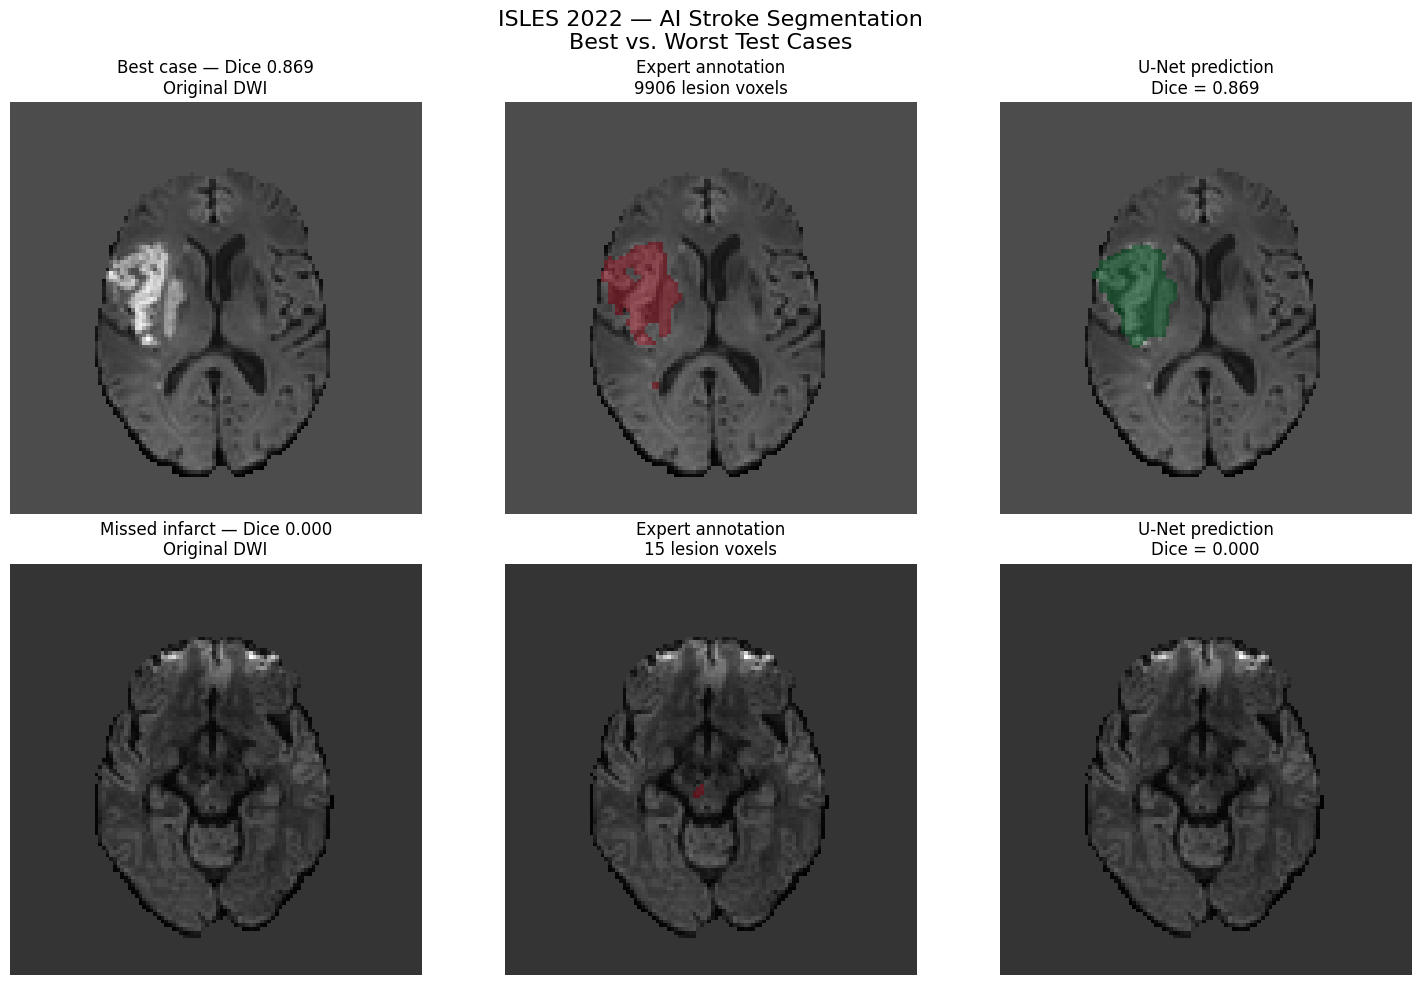

Visualization complete!


In [40]:

# ============================================================
# STEP 18: VISUALIZE BEST AND WORST TEST CASES
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt
from monai.inferers import sliding_window_inference

# ------------------------------------------------------------
# 1. SELECT TWO TEST PATIENTS
# ------------------------------------------------------------

patients = [
    ("sub-strokecase0237", "Example patient 0237"),
    ("sub-strokecase0115", "Example patient 0115")
]

# Load once and validate that exact object before using its threshold or weights.
checkpoint = torch.load(
    PROJECT_DIR / "models" / "checkpoint_best_validation.pt",
    map_location=device,
    weights_only=True
)

test_provenance = test_artifact_provenance(
    checkpoint, selection_context, selection_run_id, test_ids
)
THRESHOLD = test_provenance["threshold"]
test_df, test_manifest = read_test_artifact(PROJECT_DIR, test_provenance)
if not set(patient_id for patient_id, _ in patients).issubset(test_ids):
    raise ValueError("Example figure patients are outside the test split.")
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# ------------------------------------------------------------
# 2. CREATE A FIGURE WITH TWO ROWS AND THREE COLUMNS
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 10)
)

for row, (patient_id, description) in enumerate(patients):

    # --------------------------------------------------------
    # 3. LOAD AND PREPROCESS THE PATIENT'S MRI
    # --------------------------------------------------------

    image, expert_mask = preprocess_patient(patient_id)

    # Channel 0 is the normalized DWI.
    dwi = image[0].numpy()

    # Convert expert annotation into a binary mask.
    expert = expert_mask.squeeze().numpy() > 0

    # --------------------------------------------------------
    # 4. RUN THE TRAINED U-NET
    # --------------------------------------------------------

    with torch.no_grad():

        logits = sliding_window_inference(
            inputs=image.unsqueeze(0).to(device),
            roi_size=(64, 64, 32),
            sw_batch_size=1,
            predictor=model,
            overlap=0.25,
            sw_device=device,
            device=torch.device("cpu")
        )

        prediction = (
            torch.sigmoid(logits).squeeze().numpy()
            >= THRESHOLD
        )

    patient_row = test_df.loc[test_df["patient_id"] == patient_id].iloc[0]
    check_figure_metrics(prediction, expert, patient_row)

    # --------------------------------------------------------
    # 5. SELECT THE SLICE WITH THE LARGEST EXPERT LESION
    # --------------------------------------------------------

    lesion_area_by_slice = expert.sum(axis=(0, 1))

    slice_index = int(
        np.argmax(lesion_area_by_slice)
    )

    # Rotate all three images identically for display.
    dwi_slice = np.rot90(dwi[:, :, slice_index])
    expert_slice = np.rot90(expert[:, :, slice_index])
    prediction_slice = np.rot90(
        prediction[:, :, slice_index]
    )

    # --------------------------------------------------------
    # 6. CALCULATE FULL-VOLUME DICE
    # --------------------------------------------------------

    intersection = np.logical_and(
        expert,
        prediction
    ).sum()

    denominator = expert.sum() + prediction.sum()

    dice = (
        2 * intersection / denominator
        if denominator > 0
        else 1.0
    )

    # --------------------------------------------------------
    # 7. DISPLAY ORIGINAL DWI
    # --------------------------------------------------------

    axes[row, 0].imshow(
        dwi_slice,
        cmap="gray"
    )

    axes[row, 0].set_title(
        f"{description}\nOriginal DWI"
    )

    # --------------------------------------------------------
    # 8. DISPLAY EXPERT ANNOTATION IN RED
    # --------------------------------------------------------

    axes[row, 1].imshow(
        dwi_slice,
        cmap="gray"
    )

    axes[row, 1].imshow(
        np.ma.masked_where(
            ~expert_slice,
            expert_slice
        ),
        cmap="Reds",
        alpha=0.65,
        vmin=0,
        vmax=1
    )

    axes[row, 1].set_title(
        f"Expert annotation\n"
        f"{int(expert.sum())} lesion voxels"
    )

    # --------------------------------------------------------
    # 9. DISPLAY AI PREDICTION IN GREEN
    # --------------------------------------------------------

    axes[row, 2].imshow(
        dwi_slice,
        cmap="gray"
    )

    axes[row, 2].imshow(
        np.ma.masked_where(
            ~prediction_slice,
            prediction_slice
        ),
        cmap="Greens",
        alpha=0.65,
        vmin=0,
        vmax=1
    )

    axes[row, 2].set_title(
        f"U-Net prediction\n"
        f"Dice = {dice:.3f}"
    )

    # Hide image axes.
    for col in range(3):
        axes[row, col].axis("off")

plt.suptitle(
    "ISLES 2022 — AI Stroke Segmentation\n"
    f"Example Test Patients | Run {test_provenance['run_id']} | "
    f"Epoch {checkpoint['epoch']} | Threshold {THRESHOLD}",
    fontsize=16
)

plt.tight_layout()
figure_path = test_artifact_directory(PROJECT_DIR, test_provenance) / "example_test_patients.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
write_artifact_manifest(figure_path, test_provenance, test_manifest)
plt.show()

print("Visualization complete!")


Lesion-positive test patients: 37
Spearman correlation: 0.510
P-value: 0.001267


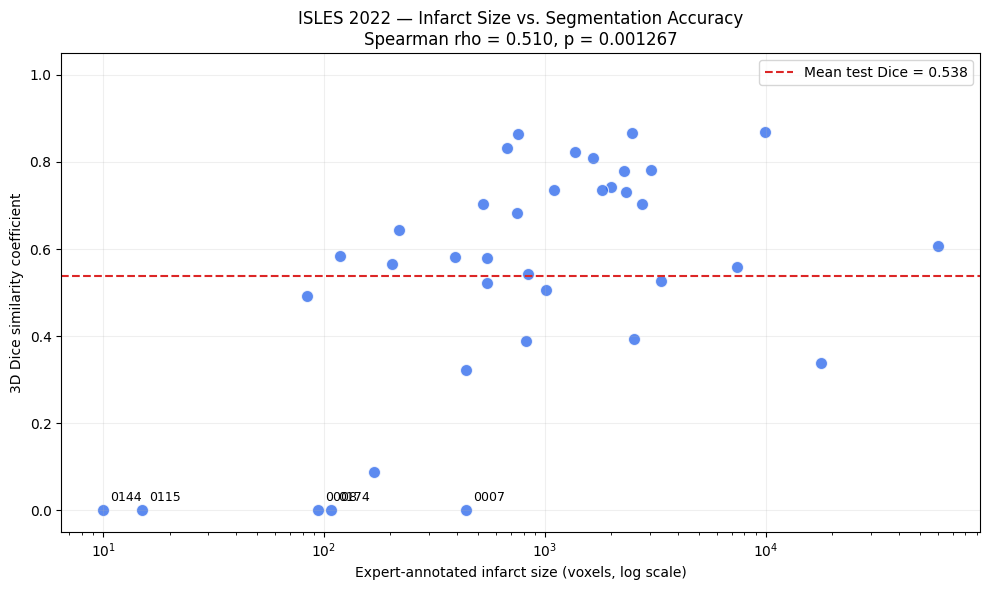

Saved scatter plot to: /content/drive/MyDrive/ISLES2022_Project/results/infarct_size_vs_dice.png


In [41]:

# ============================================================
# STEP 19A: INFARCT SIZE VS. SEGMENTATION ACCURACY
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy.stats import spearmanr

# ------------------------------------------------------------
# 1. LOAD THE TEST RESULTS
# ------------------------------------------------------------

# Reload and validate the checkpoint before resolving any artifact path.
checkpoint = torch.load(
    PROJECT_DIR / "models" / "checkpoint_best_validation.pt",
    map_location="cpu", weights_only=True
)
test_provenance = test_artifact_provenance(
    checkpoint, selection_context, selection_run_id, test_ids
)
test_df, test_manifest = read_test_artifact(PROJECT_DIR, test_provenance)
results_dir = test_artifact_directory(PROJECT_DIR, test_provenance)

# Only include patients with an expert-annotated lesion.
# The lesion-negative patient has no infarct size to plot.
positive_df = test_df[
    test_df["expert_voxels"] > 0
].copy()

# ------------------------------------------------------------
# 2. CALCULATE THE CORRELATION
# ------------------------------------------------------------

# Spearman correlation tests whether larger lesions tend
# to have higher Dice scores, without assuming a linear
# relationship.
rho, p_value = spearmanr(
    positive_df["expert_voxels"],
    positive_df["dice"]
)

print("Lesion-positive test patients:", len(positive_df))
print(f"Spearman correlation: {rho:.3f}")
print(f"P-value: {p_value:.4g}")

# ------------------------------------------------------------
# 3. CREATE THE SCATTER PLOT
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    positive_df["expert_voxels"],
    positive_df["dice"],
    s=75,
    alpha=0.75,
    color="#2563EB",
    edgecolors="white",
    linewidths=0.8
)

# Lesion sizes vary considerably, so a logarithmic
# horizontal axis makes small lesions easier to inspect.
ax.set_xscale("log")

# Show the overall test mean as a reference line.
mean_dice = positive_df["dice"].mean()

ax.axhline(
    mean_dice,
    color="#DC2626",
    linestyle="--",
    linewidth=1.5,
    label=f"Mean test Dice = {mean_dice:.3f}"
)

# Label the five lowest-Dice cases so we can identify
# them for subsequent error analysis.
worst_cases = positive_df.nsmallest(5, "dice")

for _, row in worst_cases.iterrows():
    case_number = row["patient_id"].replace(
        "sub-strokecase", ""
    )

    ax.annotate(
        case_number,
        (row["expert_voxels"], row["dice"]),
        xytext=(5, 7),
        textcoords="offset points",
        fontsize=9
    )

ax.set_xlabel(
    "Expert-annotated infarct size (voxels, log scale)"
)

ax.set_ylabel("3D Dice similarity coefficient")

ax.set_title(
    "ISLES 2022 — Infarct Size vs. Segmentation Accuracy\n"
    f"Spearman rho = {rho:.3f}, p = {p_value:.4g}"
)

ax.set_ylim(-0.05, 1.05)
ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()

# ------------------------------------------------------------
# 4. SAVE THE FIGURE
# ------------------------------------------------------------

output_path = (
    results_dir / "infarct_size_vs_dice.png"
)

fig.savefig(
    output_path,
    dpi=200,
    bbox_inches="tight"
)

write_artifact_manifest(output_path, test_provenance, test_manifest)
plt.show()

print("Saved scatter plot to:", output_path)


In [42]:

# ============================================================
# STEP 19B: VISUALIZE ALL 38 TEST PATIENTS
# ============================================================

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.backends.backend_pdf import PdfPages
from monai.inferers import sliding_window_inference
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. LOAD THE BEST SAVED MODEL
# ------------------------------------------------------------

checkpoint_path = (
    PROJECT_DIR / "models" / "checkpoint_best_validation.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

test_provenance = test_artifact_provenance(
    checkpoint, selection_context, selection_run_id, test_ids
)
THRESHOLD = test_provenance["threshold"]
test_df, test_manifest = read_test_artifact(PROJECT_DIR, test_provenance)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

results_dir = test_artifact_directory(PROJECT_DIR, test_provenance)
pdf_path = results_dir / "all_test_patient_visualizations.pdf"
PATIENTS_PER_PAGE = 4

# Use the patient order from the original test evaluation.
patient_ids = test_df["patient_id"].tolist()

# ------------------------------------------------------------
# 3. DEFINE A HELPER TO DISPLAY MASK OVERLAYS
# ------------------------------------------------------------

def display_overlay(ax, background, mask, color):
    """
    Display a grayscale DWI slice with a transparent
    colored segmentation mask on top.
    """

    ax.imshow(
        background,
        cmap="gray",
        interpolation="nearest"
    )

    # Build an RGBA overlay:
    # each pixel has red, green, blue, and alpha values.
    overlay = np.zeros(
        (*mask.shape, 4),
        dtype=np.float32
    )

    overlay[..., :3] = color

    # Only lesion pixels are visible.
    overlay[..., 3] = mask.astype(float) * 0.55

    ax.imshow(
        overlay,
        interpolation="nearest"
    )

    ax.axis("off")


# ------------------------------------------------------------
# 4. CREATE THE MULTIPAGE PDF
# ------------------------------------------------------------

pdf_temporary_path = pdf_path.with_suffix(".pdf.tmp")
with PdfPages(pdf_temporary_path) as pdf:

    for page_start in tqdm(
        range(0, len(patient_ids), PATIENTS_PER_PAGE),
        desc="Generating PDF pages"
    ):

        page_patients = patient_ids[
            page_start:page_start + PATIENTS_PER_PAGE
        ]

        # Each row is one patient.
        # Each column is one type of visualization.
        fig, axes = plt.subplots(
            len(page_patients),
            3,
            figsize=(13, 3.7 * len(page_patients)),
            squeeze=False
        )

        for row, patient_id in enumerate(page_patients):

            # ------------------------------------------------
            # 5. PREPROCESS MRI AND EXPERT ANNOTATION
            # ------------------------------------------------

            image, expert_mask = preprocess_patient(
                patient_id
            )

            dwi = image[0].numpy()

            expert = (
                expert_mask.squeeze().numpy() > 0
            )

            # ------------------------------------------------
            # 6. RUN FULL-VOLUME U-NET INFERENCE
            # ------------------------------------------------

            with torch.no_grad():

                logits = sliding_window_inference(
                    inputs=image.unsqueeze(0).to(device),
                    roi_size=(64, 64, 32),
                    sw_batch_size=1,
                    predictor=model,
                    overlap=0.25,
                    sw_device=device,
                    device=torch.device("cpu")
                )

                prediction = (
                    torch.sigmoid(logits).squeeze().numpy()
                    >= THRESHOLD
                )

            # ------------------------------------------------
            # 7. CHOOSE A REPRESENTATIVE AXIAL SLICE
            # ------------------------------------------------

            if expert.any():

                # Select the slice containing the largest
                # number of expert-labeled lesion voxels.
                slice_index = int(
                    np.argmax(expert.sum(axis=(0, 1)))
                )

            elif prediction.any():

                # For lesion-negative cases with false
                # positives, show the most affected slice.
                slice_index = int(
                    np.argmax(prediction.sum(axis=(0, 1)))
                )

            else:

                # If neither mask contains any voxels,
                # display the middle slice.
                slice_index = dwi.shape[2] // 2

            # Apply identical rotation to every panel.
            dwi_slice = np.rot90(
                dwi[:, :, slice_index]
            )

            expert_slice = np.rot90(
                expert[:, :, slice_index]
            )

            prediction_slice = np.rot90(
                prediction[:, :, slice_index]
            )

            # ------------------------------------------------
            # 8. LOOK UP THE PATIENT'S TEST DICE
            # ------------------------------------------------

            patient_row = test_df.loc[
                test_df["patient_id"] == patient_id
            ].iloc[0]

            check_figure_metrics(prediction, expert, patient_row)

            dice = float(patient_row["dice"])

            expert_voxels = int(
                patient_row["expert_voxels"]
            )

            predicted_voxels = int(
                patient_row["predicted_voxels"]
            )

            # ------------------------------------------------
            # 9. DISPLAY ORIGINAL DWI
            # ------------------------------------------------

            axes[row, 0].imshow(
                dwi_slice,
                cmap="gray",
                interpolation="nearest"
            )

            axes[row, 0].set_title(
                f"{patient_id}\nOriginal DWI",
                fontsize=10
            )

            axes[row, 0].axis("off")

            # ------------------------------------------------
            # 10. DISPLAY EXPERT MASK IN RED
            # ------------------------------------------------

            display_overlay(
                axes[row, 1],
                dwi_slice,
                expert_slice,
                color=(1.0, 0.15, 0.15)
            )

            axes[row, 1].set_title(
                f"Expert annotation\n"
                f"{expert_voxels:,} voxels",
                fontsize=10
            )

            # ------------------------------------------------
            # 11. DISPLAY AI PREDICTION IN GREEN
            # ------------------------------------------------

            display_overlay(
                axes[row, 2],
                dwi_slice,
                prediction_slice,
                color=(0.0, 0.85, 0.25)
            )

            axes[row, 2].set_title(
                f"AI prediction — Dice {dice:.3f}\n"
                f"{predicted_voxels:,} predicted voxels",
                fontsize=10
            )

        page_number = (
            page_start // PATIENTS_PER_PAGE
        ) + 1

        fig.suptitle(
            "ISLES 2022 — Held-Out Test Patients\n"
            f"Page {page_number} | Epoch {checkpoint['epoch']} | "
            f"Threshold {THRESHOLD} | Run {test_provenance['run_id']}",
            fontsize=15
        )

        fig.tight_layout(
            rect=[0, 0, 1, 0.95]
        )

        # Save this page into the PDF.
        pdf.savefig(
            fig,
            bbox_inches="tight"
        )

        # Close the figure to avoid memory accumulation.
        plt.close(fig)

os.replace(pdf_temporary_path, pdf_path)
write_artifact_manifest(pdf_path, test_provenance, test_manifest)

print("\nVisualization complete!")
print("Patients visualized:", len(patient_ids))
print("PDF saved to:", pdf_path)


Generating PDF pages:   0%|          | 0/10 [00:00<?, ?it/s]


Visualization complete!
Patients visualized: 38
PDF saved to: /content/drive/MyDrive/ISLES2022_Project/results/all_test_patient_visualizations.pdf


## Future work

The notebook already implements multimodal 3D training, validation-based threshold/checkpoint selection, a 38-patient internal test evaluation, and visualization code. These saved results have **not been independently reproduced**.

1. Release versioned configuration, split manifests, dependency versions, checkpoints, and result artifacts where permitted, then independently reproduce the workflow.
2. Add portable modules and configurable paths, mask-free inference, and spatially faithful NIfTI export.
3. Add automated tests and CI for preprocessing geometry, patch sampling, split integrity, training/checkpoint behavior, inference, and metric edge cases.
4. Assess anatomical registration quality and center effects; compare modality ablations and baselines using the same evaluation protocol.
5. Report uncertainty intervals, lesion-wise sensitivity/precision, physical-volume error, and small-lesion failures. Seek center-held-out or external validation without tuning on the existing internal test results.
6. Publish a model card and permitted aggregate figures, document resource requirements, and select an explicit code license. Obtain data from the official source and respect its separate terms.

**Data citation:** Hernandez Petzsche et al., *Scientific Data* (2022), DOI: 10.1038/s41597-022-01875-5.
